---

# False Five: Frame-Level Ball Possession

**More than a Hack 2027, Phase 1**

*FC Barcelona vs Athletic Club (LaLiga 2024-25, MD2). For each of the 199,319 tactical-video frames, decide whether Barcelona (`H`) or Athletic (`A`) has the ball, or whether the ball is dead (`D`). Ranked on possession-level `spellF1`.*

---

## Team False Five

- Farrel Athalla Putra
- Izhar Alif Akbar
- Raka Daffa Iftikhaar
- Kefas Kurnia Jonathan
- M. Fithra Rizki

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding**](#3)
4. [**External Data and Label Alignment**](#4)
5. [**Feature Engineering and Noise Simulation**](#5)
6. [**Frame Models**](#6)
7. [**Ensembling and Sequence Decoding**](#7)
8. [**Match-Specific Evidence**](#8)
9. [**Final Submission**](#9)
10. [**Evaluation Report and Error Analysis**](#10)
11. [**Conclusion and Limitations**](#11)

---

# Introduction <a name="1"></a>

---

## Overview

*More than a Hack 2027 (Metrica Sports, FC Barcelona Innovation Hub, Mobile World Capital Barcelona) asks one question about one full match: for every frame of the tactical video, who has the ball? The inputs are Metrica's automatic, uncorrected tracking of players and ball, per-frame homographies, Smart Tagging, and a second broadcast recording with its own tracking. The ball is missing on 41% of graded frames, mostly in long blocks, player tracks fragment and swap, and only the first five minutes of ground truth (17 possessions) are public.*

## Aim

*Produce a 199,319-row `frame,label` file that recovers the match's possessions as whole intervals, so that each true possession is matched one-to-one by a predicted possession with high temporal overlap. Every design choice is validated on held-out external matches, never on the 17 public possessions, and the file can be regenerated byte for byte from saved artefacts.*

## Metric

***spellF1** treats each possession (a maximal run of `H` or of `A`) as one object. Predicted and true possessions are matched one-to-one by temporal IoU, and the F1 of that matching is averaged over IoU thresholds 0.3 to 0.7. A dead-ball stretch splits possessions, so dead-ball detection matters as much as the team call. `X` abstentions are forward-filled before matching.*

$$\text{spellF1} = \frac{1}{5}\sum_{\theta \in \{0.3,0.4,0.5,0.6,0.7\}} \frac{2\,TP_\theta}{2\,TP_\theta + FP_\theta + FN_\theta}$$

***macroF1** (mean per-frame F1 over `H`, `A`, `D`) is reported beside it and breaks ties.*

## Dataset

*Match data is released by the organisers to enrolled teams and is not redistributed. Three external sources with possession and dead-ball labels are used for training and validation: the IDSSE / Sportec DFL open data (7 Bundesliga matches, CC-BY 4.0), Metrica Sports' public sample games (3 anonymised matches with tracking and events), and the PFF FC FIFA World Cup 2022 release (64 matches of broadcast tracking with event data, free after registration with PFF FC).*

```
WORK_DIR/
├── data/
|    ├── tactical/   BAR-ATH_tactical_atd.{xml,txt}, _homography.csv (+ video and Smart Tagging, unused)
|    └── broadcast/  BAR-ATH_broadcast_atd.{xml,txt}, _homography.csv
├── reference/
|    ├── pysport/    DFL_02_01_matchinformation_*.xml, DFL_04_03_positions_raw_observed_*.xml
|    ├── metrica/sample-data/data/  Sample_Game_1..3
|    └── fifa/       FIFA World Cup 2022/{Tracking Data/*.jsonl.bz2, Event Data/*/*.json, Metadata/*.json}
└── more-than-a-hack-2027/   official scorer, public 5-minute ground truth, starter code
```

**Target**
 `label` : `H` home (Barcelona) in possession, `A` away (Athletic) in possession, `D` dead ball, `X` no answer

## Approach

```
Metrica ATD (players + ball)    synced broadcast ATD (ball gap-fill, replay flag)
          |                                  |
  team-level features (268) <---------------+
          |
  LightGBM (mixture A) + BiGRU and TCN (mixtures A and B), trained on DFL + Metrica sample + PFF WC2022
  (each degraded with this match's own noise patterns, labels aligned to "controlled" possession)
          |
  greedy ensemble selection: OOF spellF1 - rhythm penalty on BAR-ATH
          |
  + log-likelihood terms on D: broadcast replay, missing-ball gap length (EM, replay-checked)
          |
  3-state Viterbi (H/A/D), switch costs chosen by the same objective
          |
  frame,label CSV + reproducibility bundle
```

---

# Initialization <a name="2"></a>

---

## Environment Setup

*Written for one rented large-GPU Linux machine (parallel workers use `fork`; on Windows everything runs serially). Expected runtime with all 64 PFF matches: PFF parsing a few minutes with 12 workers, eight LightGBM folds roughly 5 to 8 minutes each on 16 threads, eight folds of the five sequence-model fits (BiGRU A x2, BiGRU B, TCN A, TCN B) about 6 to 12 minutes per fold on the GPU, and the ensemble and decoder searches about 10 minutes, so about 2.5 hours in total. Peak memory is roughly 20 GB of RAM (training rows, validation features and the sequence chunks, which are built once per fold and shared by all sequence models).*

*Recommended order: first run all cells once with `MTAH_TINY=1` (two matches per source, two folds, a few minutes) to catch environment problems, then delete `cache/oof_*.npz` and run the full notebook.*

In [2]:
!nvidia-smi

Tue Nov 17 06:24:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 575.64.03              Driver Version: 575.64.03      CUDA Version: 12.9     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5090        On  |   00000000:01:00.0 Off |                  N/A |
|  0%   41C    P8              9W /  575W |       0MiB /  32607MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

The following cell installs all libraries used in this notebook into the running kernel's interpreter. Versions are pinned so that the submission can be regenerated.

In [3]:
import sys
!{sys.executable} -m pip install -q "numpy>=1.26,<2.3" "pandas>=2.2,<2.4" "scipy" "lightgbm==4.6.0" "numba>=0.60" "matplotlib" "gdown>=5.2" "huggingface_hub" "tqdm"
!{sys.executable} -m pip install -q "torch" --upgrade-strategy only-if-needed

## Import Libraries

In [4]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import sys
import re
import gc
import bz2
import glob
import json
import time
import shutil
import random
import zipfile
import itertools
import warnings
import subprocess
import importlib
import xml.etree.ElementTree as ET
from pathlib import Path
from multiprocessing import Pool

import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from numba import njit
import torch
import torch.nn as nn
import gdown
from huggingface_hub import snapshot_download

pd.set_option('display.width', 220)
warnings.filterwarnings('ignore', category=RuntimeWarning)
print('torch', torch.__version__, 'cuda', torch.cuda.is_available(), '| lightgbm', lgb.__version__, '| numpy', np.__version__)

torch 2.11.0+cu128 cuda True | lightgbm 4.6.0 | numpy 2.2.6


## Seed Everything

Seeds are fixed and PyTorch is put in deterministic mode. LightGBM runs with `deterministic=True` and a fixed thread count. The final probabilities are also saved, so the submission can be regenerated bit for bit by the stand-alone decode script written in section 9 even if GPU kernels differ across hardware.

In [5]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)

seed_everything(42)

## Settings

All paths, hyperparameters and switches live here. `MIXTURES` defines the two training mixtures (share of the total training weight per source), `SEQ_MEMBERS` lists the sequence models as (architecture, mixture, seeds per fold), and `RHYTHM_BAND` / `RHYTHM_LAMBDA` set the rhythm penalty used in model and decoder selection. The Drive entries are read from the environment variables `MTAH_GDRIVE_DATA` and `MTAH_GDRIVE_REFERENCE` and accept a **folder link** or a **file id / link to a zip** (zips are recommended: `gdown` lists at most 50 files per folder). `reference.zip` should contain `pysport/` (DFL), `fifa/` (PFF FC World Cup 2022, as downloaded from PFF) and optionally `metrica/sample-data/`. Fallbacks: DFL from the Hugging Face dataset `pysport/idsse-data`, Metrica sample games from GitHub, the scorer from the official repository. If the data bundle is already on disk, point `MTAH_DATA_DIR` (and `MTAH_REF_DIR`) at it and no download happens. PFF data has no public mirror (it is free after registering with PFF FC); without it the notebook still runs on DFL and Metrica only.

In [6]:
class Settings:
    SEED = 42
    WORK_DIR = Path(os.environ.get('MTAH_WORK', Path.cwd() / 'mtah_work'))
    DATA_DIR = WORK_DIR / 'data'
    REF_DIR = WORK_DIR / 'reference'
    REPO_DIR = WORK_DIR / 'more-than-a-hack-2027'
    CACHE_DIR = WORK_DIR / 'cache'
    OUT_DIR = WORK_DIR / 'outputs'
    EVAL_DIR = OUT_DIR / 'evaluation'
    FIG_DIR = OUT_DIR / 'figures'

    GDRIVE_DATA = os.environ.get('MTAH_GDRIVE_DATA', 'PASTE_DATA_ZIP_LINK')
    GDRIVE_REFERENCE = os.environ.get('MTAH_GDRIVE_REFERENCE', 'PASTE_REFERENCE_ZIP_LINK')
    SKIP_VIDEO_DOWNLOAD = True
    REPO_URL = 'https://github.com/metrica-sports/more-than-a-hack-2027.git'
    METRICA_URL = 'https://github.com/metrica-sports/sample-data.git'
    DFL_HF_REPO = 'pysport/idsse-data'

    GAME = 'BAR-ATH'
    N_FRAMES = 199319
    FPS = 25
    PITCH = (105.3, 68.0)
    HALVES = [(11185, 90652), (110808, 190198)]
    PUBLIC = (11185, 18685)
    HALFTIME_CUT = 100730

    SOURCES = ('dfl', 'metrica', 'pff')
    TRAIN_TAU = {'dfl': 50, 'metrica': 50, 'pff': 25}
    EVAL_TAU = {'dfl': (50, 75), 'metrica': (50, 75), 'pff': (25, 50)}
    SELECT_WEIGHTS = {'dfl': 1.0, 'metrica': 2.0, 'pff': 1.0}
    MIXTURES = {'A': {'dfl': 0.35, 'metrica': 0.20, 'pff': 0.45},
                'B': {'dfl': 0.45, 'metrica': 0.40, 'pff': 0.15}}
    TRAIN_SHARE = MIXTURES['A']
    MAX_PFF = 64
    MAX_DFL = 7
    MAX_MET = 3
    N_EVAL_PFF = 16
    N_FOLDS = 8
    N_NOISE_SEEDS = 2
    SUBSAMPLE = 5
    N_WORKERS = int(os.environ.get('MTAH_WORKERS', max(1, min(16, (os.cpu_count() or 2) - 2))))

    GBM_PARAMS = dict(objective='multiclass', num_class=3, learning_rate=0.05, num_leaves=63,
                      min_data_in_leaf=200, feature_fraction=0.5, bagging_fraction=0.7, bagging_freq=1,
                      lambda_l2=1.0, verbose=-1, num_threads=int(os.environ.get('MTAH_THREADS', 16)), seed=42, deterministic=True, force_row_wise=True)
    GBM_ROUNDS = 300

    SEQ_MEMBERS = [('gru', 'A', 2), ('gru', 'B', 1), ('tcn', 'A', 1), ('tcn', 'B', 1)]
    GRU_HIDDEN = 192
    TCN_HIDDEN = 192
    TCN_DILATIONS = (1, 2, 4, 8, 16, 32)
    GRU_EPOCHS = 12
    GRU_CHUNK = 512
    GRU_BATCH = 64

    ENSEMBLE_STEPS = 10
    REF_DECODER = dict(c_team=12.0, c_dead=12.0)
    RHYTHM_BAND = 0.10
    RHYTHM_LAMBDA = 0.10
    DECODER_GRID = dict(c_team=[2, 4, 6, 8, 12, 16, 20], c_dead=[6, 8, 12, 16, 24])
    MIN_DEAD_GRID = [1, 50]
    REPLAY_WEIGHTS = (1.5, -0.7)
    MISS_SHRINK = 0.5

    TEAM_NAME = 'False_Five'
    DEVICE = os.environ.get('MTAH_DEVICE') or ('cuda' if torch.cuda.is_available() else 'cpu')

    SMOKE = os.environ.get('MTAH_SMOKE') == '1'
    if SMOKE:
        MAX_PFF, MAX_DFL, N_EVAL_PFF, N_FOLDS, N_NOISE_SEEDS, SUBSAMPLE = 4, 3, 2, 3, 1, 10
        GRU_EPOCHS, GRU_HIDDEN, TCN_HIDDEN, GRU_BATCH, GRU_CHUNK, GBM_ROUNDS = 1, 32, 32, 32, 256, 150
        SEQ_MEMBERS = [('gru', 'A', 1), ('gru', 'B', 1), ('tcn', 'A', 1), ('tcn', 'B', 1)]
        DECODER_GRID = dict(c_team=[4, 12], c_dead=[12, 16])
        MIN_DEAD_GRID = [1, 50]
        ENSEMBLE_STEPS = 3
    if os.environ.get('MTAH_TINY') == '1':
        MAX_PFF, MAX_DFL, MAX_MET, N_EVAL_PFF, N_FOLDS, SUBSAMPLE = 2, 2, 2, 2, 2, 10
        DECODER_GRID = dict(c_team=[4, 12], c_dead=[12, 16])
        ENSEMBLE_STEPS = 3

CFG = Settings()
for attr_name, env in (('DATA_DIR', 'MTAH_DATA_DIR'), ('REF_DIR', 'MTAH_REF_DIR'), ('REPO_DIR', 'MTAH_REPO_DIR'),
                       ('CACHE_DIR', 'MTAH_CACHE_DIR')):
    if os.environ.get(env):
        setattr(CFG, attr_name, Path(os.environ[env]))
for p in (CFG.WORK_DIR, CFG.CACHE_DIR, CFG.OUT_DIR, CFG.EVAL_DIR, CFG.FIG_DIR, CFG.DATA_DIR, CFG.REF_DIR):
    p.mkdir(parents=True, exist_ok=True)
L_PITCH, W_PITCH = CFG.PITCH

def pmap(fn, items, chunksize=1):
    if CFG.N_WORKERS <= 1 or os.name == 'nt':
        for x in items:
            yield fn(x)
        return
    with Pool(CFG.N_WORKERS) as pool:
        yield from pool.imap_unordered(fn, items, chunksize)

print(CFG.WORK_DIR, CFG.DEVICE, 'workers', CFG.N_WORKERS)

/mtah_work cuda workers 16


## Load Dataset

The download helpers resolve the Drive entries, skip the 5 GB video files, unpack zips and normalise the folder layout so that `data/tactical`, `data/broadcast`, `reference/pysport`, `reference/fifa` and `reference/metrica` exist however the zip was rooted. Missing public sources are then fetched from their official locations.

In [7]:
def drive_id(s):
    m = re.search(r'/folders/([\w-]+)', s) or re.search(r'/d/([\w-]+)', s) or re.search(r'id=([\w-]+)', s)
    return (m.group(1) if m else s.strip()), ('/folders/' in s)

def find_dir(root, name):
    hits = sorted(Path(root).rglob(name), key=lambda p: len(p.parts))
    return hits[0] if hits else None

def fetch_drive(entry, dest, wanted_subdirs):
    if all(find_dir(dest, w) for w in wanted_subdirs):
        print('already present:', dest); return
    if entry.startswith('PASTE_'):
        print('no Drive entry configured for', dest.name, '- relying on fallbacks'); return
    fid, is_folder = drive_id(entry)
    if is_folder:
        files = gdown.download_folder(id=fid, output=str(dest), quiet=True, skip_download=True, remaining_ok=True)
        for f in files:
            if CFG.SKIP_VIDEO_DOWNLOAD and f.path.lower().endswith('.mp4'):
                continue
            target = dest / f.path
            target.parent.mkdir(parents=True, exist_ok=True)
            if not target.exists():
                gdown.download(id=f.id, output=str(target), quiet=True)
    else:
        zpath = CFG.CACHE_DIR / (dest.name + '.zip')
        if not zpath.exists():
            gdown.download(id=fid, output=str(zpath), quiet=False)
        with zipfile.ZipFile(zpath) as z:
            members = [m for m in z.namelist() if not (CFG.SKIP_VIDEO_DOWNLOAD and m.lower().endswith('.mp4'))
                       and '/.git/' not in m]
            z.extractall(dest, members)
    for w in wanted_subdirs:
        hit = find_dir(dest, w)
        if hit is not None and hit != dest / w and not (dest / w).exists():
            shutil.move(str(hit), str(dest / w))

fetch_drive(CFG.GDRIVE_DATA, CFG.DATA_DIR, ['tactical', 'broadcast'])
fetch_drive(CFG.GDRIVE_REFERENCE, CFG.REF_DIR, ['pysport', 'fifa', 'metrica'])
if not CFG.REPO_DIR.exists():
    subprocess.run(['git', 'clone', '-q', '--depth', '1', CFG.REPO_URL, str(CFG.REPO_DIR)], check=True)
sys.path.insert(0, str(CFG.REPO_DIR / 'evaluation'))
sys.path.insert(0, str(CFG.REPO_DIR))
pm = importlib.import_module('possession_metrics')

Downloading...
To: /mtah_work/cache/data.zip
100%|██████████| 5.32G/5.32G [00:55<00:00, 95.3MB/s]
Downloading...
To: /mtah_work/cache/reference.zip
100%|██████████| 3.80G/3.80G [00:49<00:00, 76.5MB/s]


In [8]:
DFL_DIR = CFG.REF_DIR / 'pysport'
if len(list(DFL_DIR.glob('DFL_04_03_positions_raw_observed_*.xml'))) < 7:
    snapshot_download(CFG.DFL_HF_REPO, repo_type='dataset', local_dir=str(DFL_DIR),
                      allow_patterns=['*matchinformation*', '*positions_raw_observed*'])
MET_DIR = CFG.REF_DIR / 'metrica' / 'sample-data' / 'data'
if not (MET_DIR / 'Sample_Game_3').exists():
    tmp = CFG.REF_DIR / 'metrica' / 'sample-data'
    subprocess.run(['git', 'clone', '-q', '--depth', '1', CFG.METRICA_URL, str(tmp)], check=False)
PFF_DIR = CFG.REF_DIR / 'fifa'
PFF_TRACK = {p.name.split('.')[0]: p for p in PFF_DIR.rglob('*.jsonl.bz2')}
PFF_EVENT = {}
for p in sorted(PFF_DIR.rglob('Event Data/*/*.json')):
    PFF_EVENT[p.stem] = p
PFF_META = {p.stem: p for p in PFF_DIR.rglob('Metadata/*.json')}
PFF_IDS = sorted([g for g in PFF_TRACK if g in PFF_EVENT and g in PFF_META], key=int)[:CFG.MAX_PFF]

TAC = CFG.DATA_DIR / 'tactical'
BRO = CFG.DATA_DIR / 'broadcast'
for p in [TAC / 'BAR-ATH_tactical_atd.txt', TAC / 'BAR-ATH_tactical_atd.xml', BRO / 'BAR-ATH_broadcast_atd.txt',
          BRO / 'BAR-ATH_broadcast_atd.xml', BRO / 'BAR-ATH_broadcast_homography.csv']:
    print(('OK   ' if p.exists() else 'MISS ') + str(p))
print('DFL matches:', len(list(DFL_DIR.glob('DFL_04_03_positions_raw_observed_*.xml'))),
      '| Metrica sample games:', len(list(MET_DIR.glob('Sample_Game_*'))), '| PFF matches:', len(PFF_IDS))

OK   /mtah_work/data/tactical/BAR-ATH_tactical_atd.txt
OK   /mtah_work/data/tactical/BAR-ATH_tactical_atd.xml
OK   /mtah_work/data/broadcast/BAR-ATH_broadcast_atd.txt
OK   /mtah_work/data/broadcast/BAR-ATH_broadcast_atd.xml
OK   /mtah_work/data/broadcast/BAR-ATH_broadcast_homography.csv
DFL matches: 7 | Metrica sample games: 3 | PFF matches: 64


---

# Data Understanding <a name="3"></a>

---

This section parses the match assets into compact arrays and measures the properties the design rests on: where the ball goes missing, what the public ground truth looks like, and what the synchronised broadcast feed adds. Every number printed is also written to `outputs/evaluation/eda_stats.json`.

## Parsing the Tracking

The raw ATD line is `frame_id:<slot x,y,speed;...>:<ball x,y,speed>` with normalised 0 to 1 coordinates. Slot team membership comes from the metadata XML (first team listed is home); `video_frame = frame_id - 1`.

In [ ]:
def parse_atd(meta_path, raw_path, cache_path):
    if Path(cache_path).exists():
        z = np.load(cache_path)
        return z['P'], z['B'], z['team']
    root = ET.parse(meta_path).getroot()
    team_ids = [t.get('id') for t in root.iter('Team')]
    team = np.array([0 if p.get('teamId') == team_ids[0] else 1 for p in root.iter('Player')], np.int8)
    S = len(team)
    with open(raw_path) as f:
        lines = f.read().splitlines()
    P = np.full((len(lines), S, 3), np.nan, np.float32)
    B = np.full((len(lines), 3), np.nan, np.float32)
    for i, line in enumerate(lines):
        a, b, c = line.split(':')
        P[int(a) - 1] = np.array(b.replace(';', ',').split(','), dtype=np.float32).reshape(S, 3)
        B[int(a) - 1] = np.array(c.split(','), dtype=np.float32)
    np.savez(cache_path, P=P, B=B, team=team)
    return P, B, team

P_tac, B_tac, team_tac = parse_atd(TAC / 'BAR-ATH_tactical_atd.xml', TAC / 'BAR-ATH_tactical_atd.txt', CFG.CACHE_DIR / 'tac.npz')
P_bro, B_bro, team_bro = parse_atd(BRO / 'BAR-ATH_broadcast_atd.xml', BRO / 'BAR-ATH_broadcast_atd.txt', CFG.CACHE_DIR / 'bro.npz')
gt_pub = pm.label_codes(pd.read_csv(CFG.REPO_DIR / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv'))
graded = np.zeros(CFG.N_FRAMES, bool)
for s, e in CFG.HALVES:
    graded[s:e] = True
print('tactical', P_tac.shape, 'broadcast', P_bro.shape, 'slots H/A', np.bincount(team_tac))
EDA = {}

## Where the Ball Goes Missing

The shape of the missingness matters more than its rate: many short flickers would be easy to bridge, long blocks are not.

In [ ]:
ball_ok = ~np.isnan(B_tac[:, 0])

def runs_of(mask, s, e):
    w = mask[s:e].astype(int)
    d = np.diff(np.concatenate([[0], w, [0]]))
    return np.flatnonzero(d == 1) + s, np.flatnonzero(d == -1) + s

gaps = []
for s, e in CFG.HALVES:
    st, en = runs_of(~ball_ok, s, e)
    gaps += list(zip(st, en))
gap_len = np.array([b - a for a, b in gaps])
n_players = (~np.isnan(P_tac[:, :, 0])).sum(1)
EDA['ball_present_graded'] = float(ball_ok[graded].mean())
EDA['ball_present_public'] = float(ball_ok[CFG.PUBLIC[0]:CFG.PUBLIC[1]].mean())
EDA['n_ball_gaps'] = int(len(gap_len))
EDA['gap_median_s'] = float(np.median(gap_len) / 25)
EDA['missing_share_in_gaps_over_10s'] = float(gap_len[gap_len > 250].sum() / gap_len.sum())
print(json.dumps(EDA, indent=1))

fig, ax = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
minute = np.arange(CFG.N_FRAMES) / 25 / 60
k = 25 * 30
ax[0].plot(minute[::k], pd.Series(ball_ok.astype(float)).rolling(k, center=True).mean().values[::k], lw=1)
ax[0].set_ylabel('ball present (30 s mean)')
ax[1].plot(minute[::k], pd.Series(n_players.astype(float)).rolling(k, center=True).mean().values[::k], lw=1, color='tab:orange')
ax[1].set_ylabel('tracked players'); ax[1].set_xlabel('video minute')
for a_ in ax:
    for s, e in CFG.HALVES:
        a_.axvspan(s / 1500, e / 1500, color='grey', alpha=0.08)
    a_.axvspan(CFG.PUBLIC[0] / 1500, CFG.PUBLIC[1] / 1500, color='green', alpha=0.15)
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'ball_presence_timeline.png', dpi=120); plt.show()

#### Insights

> The ball is present on about 59% of graded frames but on about 88% of the public five minutes, so the public window is much easier than the rest of the match and its scores are optimistic.

> Missing frames come in long blocks (median gap about 11 s, about 85% of missing frames in gaps longer than 10 s). Video spot checks inside the longest gaps show a drinks break, substitutions and goal celebrations. Section 4 shows the same relation in Metrica's own sample tracking, where the ball is missing on 94% of dead-ball frames and on under 1% of live frames.

## The Public Ground Truth

Seventeen possessions and four dead-ball stretches, each lined up with what the raw tracking shows inside it.

In [ ]:
def team_ball_dist(P, B, team):
    px, py = P[:, :, 0] * L_PITCH, P[:, :, 1] * W_PITCH
    bx, by = B[:, 0] * L_PITCH, B[:, 1] * W_PITCH
    d = np.sqrt((px - bx[:, None]) ** 2 + (py - by[:, None]) ** 2)
    dH = np.nanmin(np.where(team[None] == 0, d, np.nan), 1)
    dA = np.nanmin(np.where(team[None] == 1, d, np.nan), 1)
    return dH, dA

dH_tac, dA_tac = team_ball_dist(P_tac, B_tac, team_tac)
runs_pub = pm.valid_runs(gt_pub)
rows = []
for s, e, k in pm.segments(gt_pub, runs_pub):
    near = np.where(dH_tac[s:e] < dA_tac[s:e], 'H', 'A')[ball_ok[s:e]]
    rows.append(dict(start=s, end=e, label='HADX'[k], seconds=(e - s) / 25, ball_present=ball_ok[s:e].mean(),
                     nearest_is_label=np.mean(near == 'HADX'[k]) if len(near) else np.nan))
seg_table = pd.DataFrame(rows)
seg_table.to_csv(CFG.EVAL_DIR / 'public_gt_segments.csv', index=False)
spells_pub = [(b - a) / 25 for a, b, k in pm.possession_spells(gt_pub, runs_pub)]
EDA['public_possessions'] = len(spells_pub)
EDA['public_possession_rate_per_alive_min'] = len(spells_pub) / (np.sum(gt_pub < 2) / 1500)
seg_table.round(2)

#### Insights

> Possessions range from 0.8 s to 42 s (mean 14.2 s, median 7.6 s, 12% under 2 s) and dead-ball stretches from 5.5 s to 20 s. The public rate is about 4.2 possessions per minute of live ball, the target profile that every external label source is aligned to in section 4.

## Synchronising the Broadcast Feed

The broadcast recording is the live feed with a constant delay per half. Cross-correlating one-second means of the ball's x position finds the coarse lag, and a frame-level search minimises the median ball distance between the two trackings.

In [ ]:
def second_series(B):
    n = len(B) // 25
    return np.nanmean(B[:n * 25, 0].reshape(n, 25), 1)

st_, sb_ = second_series(B_tac), second_series(B_bro)
coarse = {}
for half, (s, e) in enumerate(CFG.HALVES, 1):
    w0, w1 = s // 25 + 60, e // 25 - 60
    best = (np.inf, 0)
    for lag in range(0, 1500):
        b0, b1 = w0 - lag, w1 - lag
        if b0 < 0 or b1 > len(sb_):
            continue
        x, y = st_[w0:w1], sb_[b0:b1]
        ok = ~np.isnan(x) & ~np.isnan(y)
        if ok.sum() > 300:
            best = min(best, (np.median(np.abs(x[ok] - y[ok])), lag))
    coarse[half] = best[1] * 25
bro_lag = {}
for half, (s, e) in enumerate(CFG.HALVES, 1):
    best = (np.inf, 0)
    for lag in range(coarse[half] - 60, coarse[half] + 61):
        t = np.arange(s, e); bb = t - lag; ok = (bb >= 0) & (bb < len(B_bro)); t, bb = t[ok], bb[ok]
        mm = ~np.isnan(B_tac[t, 0]) & ~np.isnan(B_bro[bb, 0])
        d = np.sqrt(((B_tac[t][mm, :2] - B_bro[bb][mm, :2]) ** 2 * np.array([L_PITCH ** 2, W_PITCH ** 2])).sum(1))
        best = min(best, (np.median(d), lag))
    bro_lag[half] = best[1]
    print('half %d: tactical frame t = broadcast frame t + %d (median ball distance %.2f m)' % (half, best[1], best[0]))
EDA['broadcast_lag_frames'] = bro_lag

hom_b = pd.read_csv(BRO / 'BAR-ATH_broadcast_homography.csv', usecols=['reprojection_error', 'valid'])
valid_b = hom_b.valid.values == 1
replay = np.full(CFG.N_FRAMES, np.nan, np.float32)
for half, (s, e) in enumerate(CFG.HALVES, 1):
    t = np.arange(s, e); bb = t - bro_lag[half]; ok = (bb >= 0) & (bb < len(valid_b))
    replay[t[ok]] = (~valid_b[bb[ok]]).astype(np.float32)
a, b = CFG.PUBLIC
for k, n in enumerate('HAD'):
    mm = gt_pub[a:b] == k
    EDA['broadcast_invalid_given_' + n] = float(np.nanmean(replay[a:b][mm]))
print({k: round(v, 3) for k, v in EDA.items() if k.startswith('broadcast_invalid')})

#### Insights

> The broadcast is the live feed with a fixed delay per half (about 4,014 frames in the first half and 26,920 in the second). When the broadcast has no valid homography it is showing a replay or a close-up: on the public window that happens on about 76% of dead-ball frames but only 3 to 4% of live frames. This flag is used twice: as dead-ball evidence in the final decoder, and as an independent referee for the missing-ball evidence in section 8, which is estimated without it.

In [ ]:
with open(CFG.EVAL_DIR / 'eda_stats.json', 'w') as f:
    json.dump(EDA, f, indent=1, default=float)

---

# External Data and Label Alignment <a name="4"></a>

---

Five public minutes cannot train a model, so the frame models learn from three external sources that carry exactly the two quantities the ground truth is made of, a ball status and a team in possession, on full matches. All three are converted to one format: per half, player positions `(T, slots, 2)` and the ball `(T, 2)` in metres from the pitch centre at 25 fps, the slot teams, and a label per frame (`0` H, `1` A, `2` D, `-1` unlabelled).

| source | matches | tracking | possession and dead-ball labels |
|---|---|---|---|
| DFL / IDSSE (Bundesliga) | 7 | optical, 25 fps, all 22 players | per-frame `BallPossession`, `BallStatus` from the tracking provider |
| Metrica sample games | 3 | Metrica's own optical tracking, 25 fps | derived from Metrica's event data (possession, BALL OUT, set pieces, fouls) |
| PFF FC World Cup 2022 | 64 | broadcast tracking, 29.97 fps, all 22 players (off-screen ones estimated) | derived from PFF game events (possession sequence, OUT, set-piece restarts) |

Metrica's sample games are the closest relatives of the target data: same company, same coordinate convention, and labels produced under Metrica's own possession definition. PFF adds scale (64 matches, about nine times DFL) and a possession-sequence label that turns out to match the public ground truth's rhythm almost exactly.

## DFL Positions

Each match XML has one `FrameSet` per person and half; the ball `FrameSet` carries `BallPossession` (1 home, 2 away) and `BallStatus` (1 alive, 0 dead). Attributes are read with string slicing, which keeps a 400 MB file to a few seconds.

In [14]:
RX_FS = re.compile(r'<FrameSet GameSection="(\w+)" MatchId="[^"]*" TeamId="([^"]+)" PersonId="([^"]+)"')
RX_TEAM = re.compile(r'<Team TeamId="([^"]+)"[^>]*Role="(\w+)"')

def attr(line, key):
    i = line.index(key) + len(key)
    return line[i:line.index('"', i)]

def parse_dfl(pos_path, info_path, out_path):
    if Path(out_path).exists():
        return
    roles = dict(RX_TEAM.findall(open(info_path, encoding='utf-8').read()))
    data, cur = {}, None
    with open(pos_path, encoding='utf-8') as f:
        for line in f:
            if line.startswith('<Frame '):
                rec = cur[1]
                rec[0].append(int(attr(line, 'N="'))); rec[1].append(float(attr(line, ' X="'))); rec[2].append(float(attr(line, ' Y="')))
                if cur[0]:
                    rec[3].append(int(attr(line, 'BallPossession="'))); rec[4].append(int(attr(line, 'BallStatus="')))
            elif line.startswith('<FrameSet'):
                m = RX_FS.search(line)
                key = (1 if m.group(1) == 'firstHalf' else 2, m.group(2), m.group(3))
                is_ball = m.group(2) == 'BALL'
                data[key] = ([], [], [], [], []) if is_ball else ([], [], [])
                cur = (is_ball, data[key])
    out = {}
    for half in (1, 2):
        ball = [v for k, v in data.items() if k[0] == half and k[1] == 'BALL'][0]
        n = np.array(ball[0]); n0 = n.min(); T = n.max() - n0 + 1
        B = np.full((T, 2), np.nan, np.float32); B[n - n0, 0] = ball[1]; B[n - n0, 1] = ball[2]
        poss = np.zeros(T, np.int8); status = np.zeros(T, np.int8)
        poss[n - n0] = ball[3]; status[n - n0] = ball[4]
        keys = [k for k in data if k[0] == half and k[1] in roles]
        P = np.full((T, len(keys), 2), np.nan, np.float32); team = np.zeros(len(keys), np.int8)
        for s, k in enumerate(keys):
            nn_ = np.array(data[k][0]) - n0; ok = (nn_ >= 0) & (nn_ < T)
            P[nn_[ok], s, 0] = np.array(data[k][1])[ok]; P[nn_[ok], s, 1] = np.array(data[k][2])[ok]
            team[s] = 0 if roles[k[1]] == 'home' else 1
        lab = np.where(status == 0, 2, np.where(poss == 1, 0, 1)).astype(np.int8)
        out.update({f'P{half}': P, f'team{half}': team, f'B{half}': B, f'lab{half}': lab})
    np.savez_compressed(out_path, **out)

EXT_CACHE = {s: CFG.CACHE_DIR / s for s in CFG.SOURCES}
for d in EXT_CACHE.values():
    d.mkdir(exist_ok=True)
for pos in sorted(DFL_DIR.glob('DFL_04_03_positions_raw_observed_*.xml')):
    mid = pos.stem.split('_')[-1]
    info = next(DFL_DIR.glob(f'DFL_02_01_matchinformation_*{mid}.xml'))
    parse_dfl(pos, info, EXT_CACHE['dfl'] / f'{mid}.npz')
print('DFL parsed:', len(list(EXT_CACHE['dfl'].glob('*.npz'))))

DFL parsed: 7


## Metrica Sample Games

Games 1 and 2 come as two CSVs (home and away) plus an event CSV; game 3 in the FIFA EPTS format (a text file in the same layout as the challenge ATD, an XML spec whose player order changes at substitutions, and JSON events). Labels follow Metrica's event definitions: a team holds possession from its PASS, CARRY, RECOVERY, SET PIECE or SHOT until the opponent records one of these; play stops at BALL OUT (when the ball crosses the line), at a foul (FAULT RECEIVED or a CHALLENGE with a FAULT subtype), at an offside, at a goal, or when the referee halts play, and restarts at the next SET PIECE, goal kick or first action.

In [15]:
def metrica_labels(ev, T):
    lab = np.full(T, -1, np.int8)
    marks = [x for x in ev.sort_values(['sf', 'ef']).itertuples() if x.Type != 'CARD']
    cur, dead_from = -1, None
    for i, x in enumerate(marks):
        sub = str(x.Subtype or '')
        s, en = int(x.sf), int(max(x.ef, x.sf))
        if x.Type == 'SET PIECE' or (x.Type == 'PASS' and 'GOAL KICK' in sub):
            if dead_from is None and i > 0:
                dead_from = int(max(marks[i - 1].ef, marks[i - 1].sf))
            if dead_from is not None and dead_from < s:
                lab[dead_from:s] = 2
            dead_from = None
            cur = x.Team; lab[s:] = cur
            continue
        if dead_from is not None:
            if dead_from < s:
                lab[dead_from:s] = 2
            dead_from = None
            if x.Type in ('PASS', 'CARRY', 'RECOVERY', 'SET PIECE', 'SHOT', 'BALL LOST', 'BALL OUT'):
                cur = x.Team; lab[s:] = cur
            continue
        if x.Type in ('RECOVERY', 'PASS', 'CARRY', 'SHOT') and x.Team != cur:
            cur = x.Team; lab[s:] = cur
        stops = (x.Type == 'BALL OUT' or (x.Type == 'SHOT' and (('GOAL' in sub and 'OFF' not in sub) or 'OUT' in sub))
                 or x.Type == 'FAULT RECEIVED' or (x.Type == 'CHALLENGE' and 'FAULT' in sub) or 'OFFSIDE' in sub
                 or 'FORCED' in sub or 'END HALF' in sub)
        if stops:
            dead_from = en if (x.Type in ('BALL OUT', 'SHOT') or 'OFFSIDE' in sub) else s
            lab[dead_from:] = 2
    return lab

def to_metres(P, B):
    Pm = np.stack([(P[..., 0] - 0.5) * 105.0, (P[..., 1] - 0.5) * 68.0], -1).astype(np.float32)
    Bm = np.stack([(B[:, 0] - 0.5) * 105.0, (B[:, 1] - 0.5) * 68.0], -1).astype(np.float32)
    return Pm, Bm

def parse_metrica_csv(game_dir, out_path):
    if Path(out_path).exists():
        return
    gid = Path(game_dir).name
    def read_team(side):
        df = pd.read_csv(Path(game_dir) / f'{gid}_RawTrackingData_{side}_Team.csv', skiprows=2)
        cols = df.columns.tolist()
        xy = [df.iloc[:, [cols.index(c), cols.index(c) + 1]].values for c in cols if c.startswith('Player')]
        bj = cols.index('Ball')
        return df['Period'].values, df['Frame'].values, np.stack(xy, 1).astype(np.float32), df.iloc[:, [bj, bj + 1]].values.astype(np.float32)
    per, frame, PH, Bh = read_team('Home')
    _, _, PA, _ = read_team('Away')
    ev = pd.read_csv(Path(game_dir) / f'{gid}_RawEventsData.csv')
    ev['Team'] = (ev.Team == 'Away').astype(int)
    out = {}
    for h in (1, 2):
        m = per == h
        f0 = frame[m].min()
        e = ev[ev.Period == h].copy()
        e['sf'] = e['Start Frame'] - f0; e['ef'] = e['End Frame'] - f0
        Pm, Bm = to_metres(np.concatenate([PH[m], PA[m]], 1), Bh[m])
        out.update({f'P{h}': Pm, f'team{h}': np.array([0] * PH.shape[1] + [1] * PA.shape[1], np.int8),
                    f'B{h}': Bm, f'lab{h}': metrica_labels(e, m.sum())})
    np.savez_compressed(out_path, **out)

def parse_metrica_epts(game_dir, out_path):
    if Path(out_path).exists():
        return
    gid = Path(game_dir).name
    root = ET.parse(Path(game_dir) / f'{gid}_metadata.xml').getroot()
    tids = [t.get('id') for t in root.iter('Team')]
    pteam = {p.get('id'): tids.index(p.get('teamId')) for p in root.iter('Player')}
    ch2p = {pc.get('id'): pc.get('playerId') for pc in root.iter('PlayerChannel')}
    specs = []
    for spec in root.iter('DataFormatSpecification'):
        xs = [pc.get('playerChannelId') for pc in spec.iter('PlayerChannelRef') if pc.get('playerChannelId').endswith('_x')]
        tm = np.array([pteam[ch2p[c]] for c in xs])
        specs.append((int(spec.get('startFrame')), int(spec.get('endFrame')), np.argsort(tm, kind='stable'), np.sort(tm)))
    params = {pp.findtext('Name'): pp.findtext('Value') for pp in root.iter('ProviderParameter')}
    periods = [(int(params['first_half_start']), int(params['first_half_end'])),
               (int(params['second_half_start']), int(params['second_half_end']))]
    S = len(specs[0][2])
    fr, Ps, Bs = [], [], []
    with open(Path(game_dir) / f'{gid}_tracking.txt') as f:
        for line in f:
            a_, b_, c_ = line.strip().split(':')
            fr.append(int(a_))
            Ps.append(np.array(b_.replace(';', ',').split(','), dtype=np.float32)[:2 * S].reshape(S, 2))
            Bs.append(np.array(c_.split(',')[:2], dtype=np.float32))
    fr = np.array(fr); P = np.stack(Ps); B = np.stack(Bs)
    for s0, s1, perm, _ in specs:
        m = (fr >= s0) & (fr <= s1)
        P[m] = P[m][:, perm]
    rows = []
    for e in json.load(open(Path(game_dir) / f'{gid}_events.json', encoding='utf-8'))['data']:
        sub = e.get('subtypes')
        sub = ' '.join(s['name'] for s in sub) if isinstance(sub, list) else (sub or {}).get('name')
        rows.append(dict(Team=int(e['team']['id'] != tids[0]), Type=e['type']['name'], Subtype=sub,
                         Period=e['period'], sframe=e['start']['frame'], eframe=e['end']['frame']))
    ev = pd.DataFrame(rows)
    out = {}
    for h, (s0, s1) in enumerate(periods, 1):
        m = (fr >= s0) & (fr <= s1)
        f0 = fr[m].min()
        e = ev[ev.Period == h].copy()
        e['sf'] = e.sframe - f0; e['ef'] = e.eframe - f0
        Pm, Bm = to_metres(P[m], B[m])
        out.update({f'P{h}': Pm, f'team{h}': specs[0][3].astype(np.int8), f'B{h}': Bm, f'lab{h}': metrica_labels(e, m.sum())})
    np.savez_compressed(out_path, **out)

for g in ('Sample_Game_1', 'Sample_Game_2'):
    if (MET_DIR / g).exists():
        parse_metrica_csv(MET_DIR / g, EXT_CACHE['metrica'] / f'{g}.npz')
if (MET_DIR / 'Sample_Game_3').exists():
    parse_metrica_epts(MET_DIR / 'Sample_Game_3', EXT_CACHE['metrica'] / 'Sample_Game_3.npz')
print('Metrica parsed:', len(list(EXT_CACHE['metrica'].glob('*.npz'))))

Metrica parsed: 3


## PFF FC World Cup 2022

Every PFF tracking frame carries the game event it belongs to: on-the-ball events (`OTB`) name the player's team and the team that owns the current **possession sequence** (`home_ball`), `OUT` marks the ball leaving the pitch, and the event file adds the set-piece type of each event (kick-off, throw-in, corner, goal kick, free kick, penalty, drop ball). Labels: from each `OTB` event to the next, the sequence team has the ball; the ball is dead from an `OUT` (or, for fouls and goals, from the end of the last on-the-ball event) until the next set-piece restart. Player positions use PFF's Kalman-smoothed tracks (smoothed from positions only); the ball uses the raw detections, never `ballsSmoothed`, which is placed at the event carrier and would leak the label. Frames are resampled from 29.97 to 25 fps.

In [16]:
PFF_RESTART = {'K', 'T', 'C', 'G', 'F', 'P', 'D'}

def resample(t_src, arr, t_dst):
    idx = np.clip(np.searchsorted(t_src, t_dst, side='right') - 1, 0, len(t_src) - 2)
    w = np.clip((t_dst - t_src[idx]) / np.maximum(t_src[idx + 1] - t_src[idx], 1e-9), 0, 1)
    shape = (-1,) + (1,) * (arr.ndim - 1)
    out = arr[idx] * (1 - w).reshape(shape) + arr[idx + 1] * w.reshape(shape)
    out[(t_src[idx + 1] - t_src[idx]) > 0.2] = np.nan
    return out.astype(np.float32)

def pff_labels(evdf, f0, L):
    lab = np.full(L, -1, np.int8); labseq = np.full(L, -1, np.int8)
    marks = []
    for x in evdf.sort_values('s').itertuples():
        s = int(x.s) - f0
        e = int(x.e) - f0 if x.e == x.e else s
        if x.type == 'OUT':
            marks.append((s, 'out', 0, 0, s))
        elif x.type in ('OTB', 'FIRSTKICKOFF', 'SECONDKICKOFF'):
            restart = x.sp in PFF_RESTART or x.type != 'OTB'
            marks.append((s, 'restart' if restart else 'otb', 0 if x.home else 1, 0 if x.home_ball else 1, e))
        elif x.type == 'END':
            marks.append((s, 'end', 0, 0, s))
    marks.sort(key=lambda m: m[0])
    stop_at, last_end = None, None
    for i, (s, kind, team, seqteam, e) in enumerate(marks):
        s = max(0, min(L, s))
        nxt = max(0, min(L, marks[i + 1][0])) if i + 1 < len(marks) else L
        if kind == 'out':
            stop_at = s; lab[s:nxt] = 2; labseq[s:nxt] = 2
        elif kind in ('restart', 'otb'):
            if kind == 'restart' and stop_at is None and last_end is not None:
                stop_at = last_end
            if stop_at is not None and stop_at < s:
                lab[stop_at:s] = 2; labseq[stop_at:s] = 2
            stop_at = None
            lab[s:nxt] = team; labseq[s:nxt] = seqteam
            last_end = max(s, min(L, e))
        else:
            lab[s:] = -1; labseq[s:] = -1
            break
    return lab, labseq

def parse_pff(gid):
    out_path = EXT_CACHE['pff'] / f'{gid}.npz'
    if out_path.exists():
        return gid
    meta = json.load(open(PFF_META[gid], encoding='utf-8'))
    meta = meta[0] if isinstance(meta, list) else meta
    fps = float(meta.get('fps') or 29.97)
    setpiece = {int(e['gameEventId']): (e.get('gameEvents') or {}).get('setpieceType')
                for e in json.load(open(PFF_EVENT[gid], encoding='utf-8'))}
    rows, ev, last = {1: [], 2: []}, {}, None
    with bz2.open(PFF_TRACK[gid], 'rt', encoding='utf-8') as f:
        for line in f:
            r = json.loads(line)
            per = r.get('period')
            if per not in (1, 2) or r['frameNum'] == last:
                continue
            last = r['frameNum']
            hp = r.get('homePlayersSmoothed') or r.get('homePlayers') or []
            ap = r.get('awayPlayersSmoothed') or r.get('awayPlayers') or []
            bl = r.get('balls') or []
            bxy = (bl[0]['x'], bl[0]['y']) if bl and bl[0].get('x') is not None else (np.nan, np.nan)
            rows[per].append((int(r['frameNum']), [(p['x'], p['y']) for p in hp][:11], [(p['x'], p['y']) for p in ap][:11], bxy))
            g, gid_ = r.get('game_event'), r.get('game_event_id')
            if g and gid_ is not None and gid_ == gid_ and int(gid_) not in ev:
                ev[int(gid_)] = dict(type=g.get('game_event_type'), home=g.get('home_team'), home_ball=g.get('home_ball'),
                                     s=g.get('start_frame'), e=g.get('end_frame'), period=per, sp=setpiece.get(int(gid_)))
    evdf = pd.DataFrame.from_dict(ev, orient='index').dropna(subset=['s'])
    out = {}
    for per in (1, 2):
        rr = rows[per]
        fn = np.array([x[0] for x in rr], np.int64)
        P = np.full((len(rr), 22, 2), np.nan, np.float32)
        for i, x in enumerate(rr):
            for j, xy in enumerate(x[1]):
                P[i, j] = xy
            for j, xy in enumerate(x[2]):
                P[i, 11 + j] = xy
        B = np.array([x[3] for x in rr], np.float32)
        f0 = fn.min(); L = fn.max() - f0 + 1
        lab, labseq = pff_labels(evdf[evdf.period == per], f0, L)
        t_src = (fn - f0) / fps
        t_dst = np.arange(0, t_src[-1], 1 / CFG.FPS)
        li = np.clip(np.rint(t_dst * fps).astype(int), 0, L - 1)
        out.update({f'P{per}': resample(t_src, P, t_dst), f'team{per}': np.array([0] * 11 + [1] * 11, np.int8),
                    f'B{per}': resample(t_src, B, t_dst), f'lab{per}': lab[li], f'labseq{per}': labseq[li]})
    np.savez_compressed(out_path, **out)
    return gid

t0 = time.time()
todo = [g for g in PFF_IDS if not (EXT_CACHE['pff'] / f'{g}.npz').exists()]
if todo:
    for i, g in enumerate(pmap(parse_pff, todo)):
        if i % 8 == 0:
            print('PFF parsed', i + 1, '/', len(todo), '%.0fs' % (time.time() - t0), flush=True)
print('PFF parsed:', len(list(EXT_CACHE['pff'].glob('*.npz'))))

PFF parsed 1 / 64 24s
PFF parsed 9 / 64 26s
PFF parsed 17 / 64 48s
PFF parsed 25 / 64 49s
PFF parsed 33 / 64 70s
PFF parsed 41 / 64 73s
PFF parsed 49 / 64 93s
PFF parsed 57 / 64 98s
PFF parsed: 64


## Aligning Every Source to "Controlled" Possession

The challenge changes possession only on **controlled** possession. The alignment `merge_short(lab, tau)` relabels a team spell shorter than `tau` frames to the previous team when that team regains the ball or play stops right after it, which is a touch without control. The table compares each source's possession rhythm with the public ground truth, together with how often the ball is missing in dead versus live play in each source's own tracking.

In [17]:
def merge_short(lab, tau):
    lab = lab.copy()
    if not tau:
        return lab
    for _ in range(3):
        segs = pm.segments(np.where(lab < 0, 3, lab).astype(np.int8), [(0, len(lab))])
        changed = False
        for i, (s, e, k) in enumerate(segs):
            if k >= 2 or e - s >= tau or i == 0:
                continue
            prev = segs[i - 1][2]
            nxt = segs[i + 1][2] if i + 1 < len(segs) else 2
            if prev < 2 and prev != k and (nxt == prev or nxt == 2):
                lab[s:e] = prev
                changed = True
        if not changed:
            break
    return lab

SRC_FILES = {s: sorted(EXT_CACHE[s].glob('*.npz')) for s in CFG.SOURCES}
SRC_FILES['pff'] = sorted(SRC_FILES['pff'], key=lambda p: int(p.stem))[:CFG.MAX_PFF]
SRC_FILES['dfl'] = SRC_FILES['dfl'][:CFG.MAX_DFL]
SRC_FILES['metrica'] = SRC_FILES['metrica'][:CFG.MAX_MET]
LABKEY = {'dfl': 'lab', 'metrica': 'lab', 'pff': 'labseq'}

def profile(labs, balls, tau):
    n = alive = dead = tot = 0; lens = []; mD = nD = mA = nA = 0
    for lab, B in zip(labs, balls):
        l2 = merge_short(np.where(lab < 0, 3, lab).astype(np.int8), tau)
        runs = pm.valid_runs(l2)
        sp = pm.possession_spells(l2, runs)
        n += len(sp); alive += np.sum(l2 < 2); dead += np.sum(l2 == 2); tot += np.sum(l2 < 3)
        lens += [(e - s) / 25 for s, e, _ in sp]
        miss = np.isnan(B[:, 0])
        mD += np.sum(miss & (l2 == 2)); nD += np.sum(l2 == 2); mA += np.sum(miss & (l2 < 2)); nA += np.sum(l2 < 2)
    lens = np.array(lens)
    return dict(spells_per_alive_min=n / (alive / 1500), mean_s=lens.mean(), median_s=np.median(lens),
                share_under_2s=(lens < 2).mean(), dead_share=dead / tot, ball_missing_if_dead=mD / max(nD, 1),
                ball_missing_if_alive=mA / max(nA, 1))

align_rows = []
for src in CFG.SOURCES:
    labs, balls = [], []
    for f in SRC_FILES[src]:
        z = np.load(f)
        for h in (1, 2):
            labs.append(z[f'{LABKEY[src]}{h}']); balls.append(z[f'B{h}'])
    if not labs:
        continue
    for tau in (0, 25, 50, 75):
        align_rows.append(dict(source=src, tau=tau, **profile(labs, balls, tau)))
pub_lens = np.array(spells_pub)
align_rows.append(dict(source='BAR public GT', tau='-', spells_per_alive_min=EDA['public_possession_rate_per_alive_min'],
                       mean_s=pub_lens.mean(), median_s=np.median(pub_lens), share_under_2s=(pub_lens < 2).mean(),
                       dead_share=float(np.mean(gt_pub[CFG.PUBLIC[0]:CFG.PUBLIC[1]] == 2)),
                       ball_missing_if_dead=float(np.mean(~ball_ok[CFG.PUBLIC[0]:CFG.PUBLIC[1]][gt_pub[CFG.PUBLIC[0]:CFG.PUBLIC[1]] == 2])),
                       ball_missing_if_alive=float(np.mean(~ball_ok[CFG.PUBLIC[0]:CFG.PUBLIC[1]][gt_pub[CFG.PUBLIC[0]:CFG.PUBLIC[1]] < 2]))))
align_df = pd.DataFrame(align_rows)
align_df.to_csv(CFG.EVAL_DIR / 'label_alignment.csv', index=False)
align_df.round(3)

,source,tau,spells_per_alive_min,mean_s,median_s,share_under_2s,dead_share,ball_missing_if_dead,ball_missing_if_alive
0,dfl,0,8.301,7.228,3.68,0.300,0.448,0.000,0.000
1,dfl,25,6.934,8.652,4.80,0.178,0.448,0.000,0.000
2,dfl,50,5.500,10.909,6.60,0.046,0.448,0.000,0.000
3,dfl,75,4.597,13.053,8.52,0.048,0.448,0.000,0.000
4,metrica,0,6.039,9.936,5.36,0.225,0.391,0.939,0.007
5,metrica,25,5.451,11.006,6.48,0.149,0.391,0.939,0.007
6,metrica,50,4.594,13.061,8.58,0.039,0.391,0.939,0.007
7,metrica,75,3.995,15.019,10.48,0.043,0.391,0.939,0.007
8,pff,0,4.647,12.912,7.04,0.140,0.413,0.704,0.060
9,pff,25,4.450,13.484,7.60,0.112,0.413,0.704,0.060


## The Rhythm Reference

The models are scored against each source's labels at the `EVAL_TAU` alignments, so the possession rate those labels imply is the rate a well-calibrated prediction on BAR-ATH should show. The reference is the per-source rate averaged over its `EVAL_TAU` values, then averaged over sources with `SELECT_WEIGHTS`. It uses external labels only; the public ground truth rate is printed for comparison and is not used.

In [18]:
src_rates = {}
for src in CFG.SOURCES:
    sub_ = align_df[(align_df.source == src) & align_df.tau.isin(list(CFG.EVAL_TAU[src]))]
    if len(sub_):
        src_rates[src] = float(sub_.spells_per_alive_min.mean())
sw_ = np.array([CFG.SELECT_WEIGHTS[s] for s in src_rates])
RHYTHM_TARGET = float(np.dot(sw_, list(src_rates.values())) / sw_.sum())
RHYTHM_LOW, RHYTHM_HIGH = RHYTHM_TARGET / (1 + CFG.RHYTHM_BAND), RHYTHM_TARGET * (1 + CFG.RHYTHM_BAND)
EDA['rhythm_reference'] = dict(per_source=src_rates, target=RHYTHM_TARGET, band=[RHYTHM_LOW, RHYTHM_HIGH])
print('possessions per live minute, per source at EVAL_TAU:', {k: round(v, 2) for k, v in src_rates.items()})
print('rhythm reference %.2f, band %.2f to %.2f (public ground truth, not used: %.2f)'
      % (RHYTHM_TARGET, RHYTHM_LOW, RHYTHM_HIGH, EDA['public_possession_rate_per_alive_min']))

possessions per live minute, per source at EVAL_TAU: {'dfl': 5.05, 'metrica': 4.29, 'pff': 4.16}
rhythm reference 4.45, band 4.04 to 4.89 (public ground truth, not used: 4.23)


#### Insights

> The three sources disagree in raw rhythm but align cleanly. PFF's possession-sequence label needs almost no merging: at `tau = 25` it gives about 4.5 possessions per live minute with a median of 7.4 s and 11% under 2 s, against 4.2, 7.6 s and 12% in the public ground truth. DFL's touch-level label needs `tau` 50 to 75 and Metrica's event-derived label `tau` about 50 to reach the same profile, so those are the training alignments.

> In Metrica's own sample tracking the ball is missing on about 94% of dead-ball frames and under 1% of live frames, and in PFF's broadcast tracking on about 70% and 5%. Missing ball is therefore strong dead-ball evidence in general, but how strong depends on the tracker, which is why its weight for BAR-ATH is estimated on BAR-ATH itself (section 8) rather than learned from the external sources.

---

# Feature Engineering and Noise Simulation <a name="5"></a>

---

The tracking has no player identities and slots swap, so every feature is team-level and permutation-invariant. All coordinates are in a common "home frame": metres from the pitch centre, home team attacking +x. Every per-team feature exists twice (`h_*`, `a_*`), so a home/away swap is an exact column permutation, used to double the training data and to stop the models from learning that the home side has the ball.

## Per-Frame Team Features

Shape (centroid, spread, defensive and attacking line, width), movement (speed relative to the sequence median, share running and walking, speed along the attacking direction), pressure (mean distance to the nearest opponent) and ball relations (nearest player per team, players within 5 m, ball outside the pitch, ball speed, time since and until the ball was last seen), each also summarised over centred 1, 3 and 9 s windows and 2 and 6 s past and future windows.

In [19]:
HALF_L, HALF_W = 52.65, 34.0

def nan_roll(x, w, mode='center'):
    x = np.asarray(x, np.float64)
    ok = ~np.isnan(x)
    cs = np.concatenate([[0.0], np.cumsum(np.where(ok, x, 0.0))])
    cn = np.concatenate([[0.0], np.cumsum(ok)])
    T = len(x); i = np.arange(T)
    if mode == 'center':
        lo, hi = np.clip(i - w // 2, 0, T), np.clip(i + w // 2 + 1, 0, T)
    elif mode == 'past':
        lo, hi = np.clip(i - w + 1, 0, T), i + 1
    else:
        lo, hi = i, np.clip(i + w, 0, T)
    with np.errstate(invalid='ignore', divide='ignore'):
        return ((cs[hi] - cs[lo]) / (cn[hi] - cn[lo])).astype(np.float32)

def run_since(mask):
    idx = np.where(mask, np.arange(len(mask)), -10 ** 6)
    return np.minimum(np.arange(len(mask)) - np.maximum.accumulate(idx), 10 ** 5)

def frame_features(P, team, B, ball_noise=None):
    T = len(P)
    f = {}
    V = np.full_like(P, np.nan)
    V[2:-2] = (P[4:] - P[:-4]) * (25 / 4.0)
    spd = np.sqrt((V ** 2).sum(-1))
    V[spd > 12.0] = np.nan
    spd[spd > 12.0] = np.nan
    for k, pre, sgn in ((0, 'h_', 1.0), (1, 'a_', -1.0)):
        m = team == k
        X = P[:, m, 0] * sgn; Y = P[:, m, 1]; ok = ~np.isnan(X); n = ok.sum(1).astype(np.float32)
        sp = spd[:, m]
        f[pre + 'n'] = n
        f[pre + 'cx'] = np.nanmean(X, 1); f[pre + 'cy'] = np.nanmean(Y, 1)
        f[pre + 'sx'] = np.nanstd(X, 1); f[pre + 'sy'] = np.nanstd(Y, 1)
        Xs = np.sort(np.where(ok, X, np.inf), 1); Xd = np.sort(np.where(ok, X, -np.inf), 1)
        f[pre + 'line_def'] = np.where(n >= 3, Xs[:, 1], np.nan)
        f[pre + 'line_att'] = np.where(n >= 2, Xd[:, -1], np.nan)
        f[pre + 'ext_x'] = f[pre + 'line_att'] - f[pre + 'line_def']
        f[pre + 'ext_y'] = np.nanmax(Y, 1) - np.nanmin(Y, 1)
        f[pre + 'n_opphalf'] = np.sum(X > 0, 1) / np.maximum(n, 1)
        f[pre + 'n_final3'] = np.sum(X > 17.5, 1) / np.maximum(n, 1)
        f[pre + 'n_ownthird'] = np.sum(X < -17.5, 1) / np.maximum(n, 1)
        f[pre + 'spd'] = np.nanmean(sp, 1); f[pre + 'spd_max'] = np.nanmax(sp, 1)
        f[pre + 'run'] = np.nansum(sp > 4.0, 1) / np.maximum(n, 1)
        f[pre + 'walk'] = np.nansum(sp < 1.0, 1) / np.maximum(n, 1)
        f[pre + 'vx'] = np.nanmean(V[:, m, 0] * sgn, 1)
        f[pre + 'vy_abs'] = np.nanmean(np.abs(V[:, m, 1]), 1)
    hm, am = team == 0, team == 1
    near_h = np.full(T, np.nan, np.float32); near_a = np.full(T, np.nan, np.float32); min_pair = np.full(T, np.nan, np.float32)
    for c0 in range(0, T, 20000):
        D = np.sqrt(((P[c0:c0 + 20000, hm][:, :, None] - P[c0:c0 + 20000, am][:, None]) ** 2).sum(-1))
        Di = np.where(np.isnan(D), np.inf, D)
        mh = Di.min(2); mh[~np.isfinite(mh)] = np.nan
        ma = Di.min(1); ma[~np.isfinite(ma)] = np.nan
        near_h[c0:c0 + 20000] = np.nanmean(mh, 1); near_a[c0:c0 + 20000] = np.nanmean(ma, 1)
        min_pair[c0:c0 + 20000] = Di.min((1, 2))
    min_pair[~np.isfinite(min_pair)] = np.nan
    f['h_press'], f['a_press'], f['min_pair'] = near_h, near_a, min_pair
    f['all_spd'] = np.nanmean(spd, 1)
    f['all_walk'] = np.nansum(spd < 1.0, 1) / np.maximum((~np.isnan(spd)).sum(1), 1)
    f['all_n'] = (~np.isnan(P[:, :, 0])).sum(1).astype(np.float32)
    f['cdx'] = f['h_cx'] + f['a_cx']
    f['all_cx_abs'] = np.abs(np.nanmean(P[:, :, 0], 1)); f['all_sx'] = np.nanstd(P[:, :, 0], 1)
    bx, by = B[:, 0].astype(np.float64).copy(), B[:, 1].astype(np.float64).copy()
    if ball_noise:
        rng = np.random.RandomState(ball_noise[1])
        bx += rng.normal(0, ball_noise[0], T); by += rng.normal(0, ball_noise[0], T)
    have = ~np.isnan(bx)
    f['ball_have'] = have.astype(np.float32)
    f['ball_since'] = np.minimum(run_since(have), 2500).astype(np.float32)
    f['ball_until'] = np.minimum(run_since(have[::-1])[::-1], 2500).astype(np.float32)
    f['ball_gap'] = np.where(have, 0, f['ball_since'] + f['ball_until']).astype(np.float32)
    f['h_bx'] = bx; f['a_bx'] = -bx; f['b_y_abs'] = np.abs(by)
    f['b_out'] = np.maximum(np.abs(bx) - HALF_L, np.abs(by) - HALF_W)
    bv = np.full((T, 2), np.nan)
    bv[2:-2, 0] = (bx[4:] - bx[:-4]) * 25 / 4; bv[2:-2, 1] = (by[4:] - by[:-4]) * 25 / 4
    bs = np.sqrt((bv ** 2).sum(1)); bs[bs > 40] = np.nan
    f['b_spd'] = bs
    for k, pre in ((0, 'h_'), (1, 'a_')):
        m = team == k
        d = np.sqrt((P[:, m, 0] - bx[:, None]) ** 2 + (P[:, m, 1] - by[:, None]) ** 2)
        ds = np.sort(np.where(np.isnan(d), np.inf, d), 1)
        f[pre + 'bd1'] = np.where(np.isfinite(ds[:, 0]), ds[:, 0], np.nan)
        f[pre + 'bd2'] = np.where(np.isfinite(ds[:, 1]), ds[:, 1], np.nan)
        f[pre + 'bn5'] = np.where(have, np.sum(d < 5, 1), np.nan)
    f['bd_diff'] = f['h_bd1'] - f['a_bd1']
    f['b_near_h'] = np.where(have, (f['h_bd1'] < f['a_bd1']).astype(np.float32), np.nan)
    f['b_ctrl_h'] = np.where(have & (f['h_bd1'] < 1.5) & (f['h_bd1'] < f['a_bd1']), 1.0,
                             np.where(have & (f['a_bd1'] < 1.5) & (f['a_bd1'] < f['h_bd1']), 0.0, np.nan))
    busy = f['all_n'] >= 15
    ref = np.nanmedian(f['all_spd'][busy]) if busy.any() else np.nan
    for k in ('h_spd', 'a_spd', 'all_spd', 'h_spd_max', 'a_spd_max', 'b_spd'):
        f[k + '_rel'] = f[k] / ref
    return {k: np.asarray(v, np.float32) for k, v in f.items()}

ROLL_KEYS = ['h_spd_rel', 'a_spd_rel', 'all_spd_rel', 'b_spd_rel', 'h_cx', 'a_cx', 'h_sx', 'a_sx', 'h_sy', 'a_sy',
             'h_line_def', 'a_line_def', 'h_line_att', 'a_line_att', 'h_spd', 'a_spd', 'h_run', 'a_run', 'h_walk', 'a_walk',
             'h_vx', 'a_vx', 'h_press', 'a_press', 'h_n_opphalf', 'a_n_opphalf', 'h_n_final3', 'a_n_final3', 'all_spd',
             'all_walk', 'all_n', 'min_pair', 'h_ext_y', 'a_ext_y', 'h_ext_x', 'a_ext_x', 'ball_have', 'h_bx', 'a_bx',
             'b_y_abs', 'b_out', 'b_spd', 'h_bd1', 'a_bd1', 'bd_diff', 'b_near_h', 'b_ctrl_h', 'h_bn5', 'a_bn5']
PF_KEYS = ['all_spd_rel', 'b_near_h', 'b_ctrl_h', 'h_vx', 'a_vx', 'all_spd', 'h_cx', 'a_cx', 'ball_have', 'b_out',
           'b_spd', 'h_press', 'a_press']

def build_matrix(P, team, B, ball_noise=None):
    f = frame_features(P, team, B, ball_noise)
    cols = dict(f)
    for k in ROLL_KEYS:
        for w in (25, 75, 225):
            cols[f'{k}_m{w}'] = nan_roll(f[k], w, 'center')
    for k in PF_KEYS:
        for w in (50, 150):
            cols[f'{k}_p{w}'] = nan_roll(f[k], w, 'past')
            cols[f'{k}_f{w}'] = nan_roll(f[k], w, 'future')
    names = sorted(cols)
    return np.stack([cols[n] for n in names], 1).astype(np.float32), names

def swap_X(X, names):
    pos = {n: i for i, n in enumerate(names)}
    idx = [pos[('a_' + n[2:]) if n.startswith('h_') else ('h_' + n[2:]) if n.startswith('a_') else n] for n in names]
    Y = X[:, idx].astype(np.float32)
    for j, n in enumerate(names):
        if n.startswith('bd_diff'):
            Y[:, j] = -Y[:, j]
        if n.startswith('b_near_h') or n.startswith('b_ctrl_h'):
            Y[:, j] = 1.0 - Y[:, j]
    return Y

def swap_y(y):
    return np.where(y >= 2, y, 1 - y).astype(y.dtype)

## BAR-ATH Feature Matrix with Broadcast Gap-Fill

The tactical ball is filled from the synchronised broadcast ball wherever the tactical ball is missing, the broadcast homography is valid with reprojection error below 5, and the broadcast point is not an isolated jump of more than 3 m. Barcelona attacks to the right in the first half, so the second half is rotated by 180 degrees to keep the home frame.

In [20]:
def merge_broadcast_ball(B_tac, B_bro, hom_b, lags):
    B = B_tac[:, :2].copy()
    ok_b = (hom_b.valid.values == 1) & (hom_b.reprojection_error.values < 5)
    filled = 0
    for half, (s, e) in enumerate(CFG.HALVES, 1):
        t = np.arange(s, e); bb = t - lags[half]; ok = (bb >= 0) & (bb < len(B_bro)); t, bb = t[ok], bb[ok]
        pts = B_bro[bb, :2]
        d1 = np.r_[np.inf, np.sqrt((np.diff(pts[:, 0]) * L_PITCH) ** 2 + (np.diff(pts[:, 1]) * W_PITCH) ** 2)]
        d2 = np.r_[d1[1:], np.inf]
        use = np.isnan(B[t, 0]) & ~np.isnan(pts[:, 0]) & ok_b[bb] & ~((d1 > 3) & (d2 > 3))
        B[t[use]] = pts[use]; filled += use.sum()
    print('ball frames filled from broadcast:', int(filled))
    return B

def bar_home_frame(P, B):
    Pm = np.stack([(P[..., 0] - 0.5) * L_PITCH, (P[..., 1] - 0.5) * W_PITCH], -1).astype(np.float32)
    Bm = np.stack([(B[:, 0] - 0.5) * L_PITCH, (B[:, 1] - 0.5) * W_PITCH], -1).astype(np.float32)
    Pm[CFG.HALFTIME_CUT:] *= -1; Bm[CFG.HALFTIME_CUT:] *= -1
    return Pm, Bm

B_merged = merge_broadcast_ball(B_tac, B_bro, hom_b, bro_lag)
Pm_bar, Bm_bar = bar_home_frame(P_tac[..., :2], B_merged)
c = CFG.HALFTIME_CUT
Xa_, FEATS = build_matrix(Pm_bar[:c], team_tac, Bm_bar[:c])
Xb_, _ = build_matrix(Pm_bar[c:], team_tac, Bm_bar[c:])
X_BAR = np.concatenate([Xa_, Xb_]); del Xa_, Xb_, P_bro
gc.collect()
print('BAR feature matrix', X_BAR.shape)

ball frames filled from broadcast: 8049
BAR feature matrix (199319, 268)


## Simulating Metrica ATD Noise on the External Tracking

The external tracking is cleaner than the automatic BAR-ATH tracking, so every training and validation half is degraded with BAR-ATH's own noise patterns: the exact ball-missing mask from a random offset (gap lengths and clustering stay realistic), the per-frame number of tracked players per team (dropped in 10 s blocks by a random priority), a slowly varying per-player position bias (iid jitter inflates speeds and broke the dead-ball signal in early tests) and 0.4 m ball noise. The missing-ball mask is copied independently of the label, so the frame models cannot learn "missing ball means dead ball" from the external data. That relation is real on BAR-ATH but its strength is specific to this tracker, so it is estimated on BAR-ATH itself in section 8 and enters the decoder as an explicit, checkable term.

In [21]:
gidx = np.concatenate([np.arange(s, e) for s, e in CFG.HALVES])
NOISE_MISS = np.isnan(B_merged[gidx, 0])
okp = ~np.isnan(P_tac[gidx, :, 0])
NOISE_NH = np.minimum(okp[:, team_tac == 0].sum(1), 11)
NOISE_NA = np.minimum(okp[:, team_tac == 1].sum(1), 11)
del okp, P_tac, Pm_bar, Bm_bar, dH_tac, dA_tac
gc.collect()

def simulate(Pm, team, Bm, rng, block=250):
    T = len(Bm)
    idx = (np.arange(T) + rng.randint(0, len(NOISE_MISS))) % len(NOISE_MISS)
    B2 = Bm.copy(); B2[NOISE_MISS[idx]] = np.nan
    nb = T // 50 + 2
    off = rng.normal(0, 0.3, (nb, Pm.shape[1], 2)).astype(np.float32)
    tt = np.arange(T) / 50.0; i0 = tt.astype(int); fr = (tt - i0)[:, None, None]
    P2 = Pm + off[i0] * (1 - fr) + off[i0 + 1] * fr
    for k, cnt in ((0, NOISE_NH[idx]), (1, NOISE_NA[idx])):
        slots = np.flatnonzero(team == k)
        for b0 in range(0, T, block):
            sl = slice(b0, b0 + block)
            order = slots[rng.permutation(len(slots))]
            present = ~np.isnan(Pm[sl][:, order, 0])
            drop = (np.cumsum(present, 1) > cnt[sl][:, None]) & present
            sub = P2[sl]
            for j, s_ in enumerate(order):
                sub[drop[:, j], s_] = np.nan
    return P2.astype(np.float32), B2

def load_half(src, path, h):
    z = np.load(path)
    P, team, B, lab = z[f'P{h}'], z[f'team{h}'], z[f'B{h}'], z[f'{LABKEY[src]}{h}']
    ok = np.flatnonzero(lab >= 0)
    a_, b_ = ok.min(), ok.max() + 1
    P, B, lab = P[a_:b_].astype(np.float32), B[a_:b_].astype(np.float32), lab[a_:b_]
    if np.nanmean(P[:50, team == 0, 0]) > np.nanmean(P[:50, team == 1, 0]):
        P, B = -P, -B
    return P, team, B, lab

def half_matrix(src, path, h, seed):
    P, team, B, lab = load_half(src, path, h)
    P2, B2 = simulate(P, team, B, np.random.RandomState(seed))
    X, _ = build_matrix(P2, team, B2, ball_noise=(0.4, seed))
    return X, lab

## Training and Validation Sets

Every external half is a unit. Matches used for validation (all DFL and Metrica matches and the first `N_EVAL_PFF` PFF matches) are spread over `N_FOLDS` grouped folds, so each is held out exactly once; the remaining PFF matches are always in training. Training rows are every fifth frame (5 fps) under independent noise draws; validation features are built once per held-out half at full resolution with a separate seed and shared by every model, so all models are scored on identical inputs.

In [22]:
HALF_KEYS = []
for src in CFG.SOURCES:
    for f in SRC_FILES[src]:
        HALF_KEYS += [(src, str(f), h) for h in (1, 2)]
match_ids = {}
for src in CFG.SOURCES:
    ms = [Path(f).stem for f in SRC_FILES[src]]
    n_eval = CFG.N_EVAL_PFF if src == 'pff' else len(ms)
    for i, m in enumerate(ms):
        match_ids[(src, m)] = (i % CFG.N_FOLDS) if i < n_eval else -1
HALF_FOLD = np.array([match_ids[(s, Path(p).stem)] for s, p, h in HALF_KEYS])
HALF_SRC = np.array([s for s, p, h in HALF_KEYS])
print('halves per source', {s: int((HALF_SRC == s).sum()) for s in CFG.SOURCES},
      '| validation halves', int((HALF_FOLD >= 0).sum()))

def train_job(args):
    i, seed_k = args
    src, path, h = HALF_KEYS[i]
    seed = 1000 * i + seed_k
    X, lab = half_matrix(src, path, h, seed)
    y = merge_short(lab, CFG.TRAIN_TAU[src])
    rng = np.random.RandomState(seed)
    sel = np.arange(rng.randint(CFG.SUBSAMPLE), len(X), CFG.SUBSAMPLE)
    sel = sel[y[sel] >= 0]
    return i, seed_k, X[sel].astype(np.float16), y[sel].astype(np.int8), sel.astype(np.int32)

def val_job(i):
    src, path, h = HALF_KEYS[i]
    X, lab = half_matrix(src, path, h, 900000 + i)
    return i, X.astype(np.float16), lab

jobs = [(i, k) for i in range(len(HALF_KEYS)) for k in range(1 if HALF_SRC[i] == 'pff' else CFG.N_NOISE_SEEDS)]
parts = []
t0 = time.time()
for n_done, r in enumerate(pmap(train_job, jobs, chunksize=2)):
    parts.append(r)
    if n_done % 25 == 0:
        print('training halves', n_done, '/', len(jobs), '%.0fs' % (time.time() - t0), flush=True)
parts.sort(key=lambda r: (r[0], r[1]))
TRAIN_X = np.concatenate([r[2] for r in parts]); TRAIN_Y = np.concatenate([r[3] for r in parts])
TRAIN_I = np.concatenate([np.full(len(r[3]), r[0], np.int32) for r in parts])
TRAIN_S = np.concatenate([np.full(len(r[3]), r[1], np.int8) for r in parts])
TRAIN_T = np.concatenate([r[4] for r in parts])
TRAIN_FOLD = HALF_FOLD[TRAIN_I]; TRAIN_SRC = HALF_SRC[TRAIN_I]
del parts; gc.collect()

VAL_X, VAL_LAB = {}, {}
for i, X, lab in pmap(val_job, [i for i in range(len(HALF_KEYS)) if HALF_FOLD[i] >= 0]):
    VAL_X[i], VAL_LAB[i] = X, lab
VAL_KEYS = sorted(VAL_X)
print('training rows', TRAIN_X.shape, 'class mix', np.round(np.bincount(TRAIN_Y) / len(TRAIN_Y), 3),
      '| validation halves', len(VAL_KEYS), '| %.0fs' % (time.time() - t0))

halves per source {'dfl': 14, 'metrica': 6, 'pff': 128} | validation halves 52
training halves 0 / 168 2s
training halves 25 / 168 2s
training halves 50 / 168 4s
training halves 75 / 168 5s
training halves 100 / 168 6s
training halves 125 / 168 7s
training halves 150 / 168 8s
training rows (2518487, 268) class mix [0.298 0.285 0.417] | validation halves 52 | 15s


---

# Frame Models <a name="6"></a>

---

Each model outputs per-frame probabilities over `H`, `A`, `D`. There are five ensemble members: LightGBM (mixture A), and the BiGRU and the TCN, each on mixtures A and B. All follow the same protocol: one model per grouped fold, out-of-fold (OOF) predictions on the fixed validation features, and the BAR-ATH prediction is the average of the fold models (so no separate final fit is needed and every BAR prediction comes from models that were also validated). OOF predictions are cached so that ensembling and decoding can be re-run without retraining.

## Evaluation Helpers

The score that matters is the official `spellF1` after decoding, computed per held-out half against that source's labels aligned at two `tau` values (`EVAL_TAU`), averaged per source, and then averaged over the sources with `SELECT_WEIGHTS` so that the 32 PFF validation halves do not outvote the 6 Metrica ones. Metrica counts double: it is the same tracking company and labelling convention as the target. The scorer calls the official `spell_scores` and `macro_f1` directly (identical numbers to `evaluate`, without the transition and bootstrap statistics), and also returns predicted and labelled possessions per live minute for each source.

Selection uses one objective: OOF spellF1 minus a rhythm penalty, `RHYTHM_LAMBDA * max(0, |log(rate / reference)| - log(1 + RHYTHM_BAND))`, where `rate` is the decoded BAR-ATH possession rate. Inside the band the penalty is zero, so the OOF score alone decides; outside it, a 20% rhythm error costs about 0.009, roughly the spread of OOF scores between neighbouring settings.

In [23]:
@njit(cache=True)
def _viterbi_dur(lp, cost, kmin):
    T = lp.shape[0]
    off = np.zeros(4, np.int64)
    for k in range(3):
        off[k + 1] = off[k] + kmin[k]
    S = off[3]
    lab = np.zeros(S, np.int64)
    for k in range(3):
        for i in range(kmin[k]):
            lab[off[k] + i] = k
    NEG = -1e18
    sc = np.full(S, NEG)
    for k in range(3):
        sc[off[k]] = lp[0, k]
    back = np.zeros((T, S), np.int32)
    new = np.empty(S)
    for t in range(1, T):
        for j in range(3):
            best = NEG; bi = -1
            for i in range(3):
                if i == j:
                    continue
                v = sc[off[i + 1] - 1] - cost[i, j]
                if v > best:
                    best = v; bi = off[i + 1] - 1
            if kmin[j] == 1:
                if sc[off[j]] >= best:
                    best = sc[off[j]]; bi = off[j]
            new[off[j]] = best + lp[t, j]
            back[t, off[j]] = bi
            for s in range(1, kmin[j]):
                st = off[j] + s
                if s == kmin[j] - 1 and sc[st] > sc[st - 1]:
                    new[st] = sc[st] + lp[t, j]; back[t, st] = st
                else:
                    new[st] = sc[st - 1] + lp[t, j]; back[t, st] = st - 1
        for s in range(S):
            sc[s] = new[s]
    bs = 0
    for s in range(S):
        if sc[s] > sc[bs]:
            bs = s
    path = np.zeros(T, np.int8)
    s = bs
    for t in range(T - 1, -1, -1):
        path[t] = lab[s]
        if t > 0:
            s = back[t, s]
    return path

def decode(prob, runs, c_team=12.0, c_dead=12.0, extra_logp=None, min_dead=1, min_team=1):
    lp = np.log(np.clip(prob.astype(np.float64), 1e-4, 1.0))
    if extra_logp is not None:
        lp = lp + extra_logp
    cost = np.array([[0, c_team, c_dead], [c_team, 0, c_dead], [c_dead, c_dead, 0]], np.float64)
    kmin = np.array([min_team, min_team, min_dead], np.int64)
    out = np.full(len(prob), 3, np.int8)
    for s, e in runs:
        out[s:e] = _viterbi_dur(np.ascontiguousarray(lp[s:e]), cost, kmin)
    return out

VAL_SRC = {i: HALF_SRC[i] for i in VAL_KEYS}
VAL_GT = {i: {tau: merge_short(np.where(VAL_LAB[i] < 0, 3, VAL_LAB[i]).astype(np.int8), tau)
              for tau in CFG.EVAL_TAU[VAL_SRC[i]]} for i in VAL_KEYS}

def fast_eval(g, pred):
    runs = pm.valid_runs(g)
    sp = pm.spell_scores(g, pred, runs)
    mf = pm.macro_f1(pm.scored_confusion(pm.confusion(g, pred)))
    return sp['mean_f1'], mf, sp['n_pred'], sp['n_gt'], int(np.sum(pred < 2)), int(np.sum(g < 2))

def _score_half(args):
    i, kw = args
    prob = _SCORING[i]
    pred = decode(prob, [(0, len(prob))], **kw)
    gts = VAL_GT[i]
    pred = np.where(next(iter(gts.values())) == 3, 3, pred).astype(np.int8)
    rs = [fast_eval(g, pred) for g in gts.values()]
    r0 = rs[0]
    return (i, float(np.mean([r[0] for r in rs])), float(np.mean([r[1] for r in rs])),
            r0[2], float(np.mean([r[3] for r in rs])), r0[4], float(np.mean([r[5] for r in rs])))

def oof_score(oof, detail=False, **kw):
    global _SCORING
    _SCORING = oof
    res = list(pmap(_score_half, [(i, kw) for i in VAL_KEYS if i in oof], chunksize=2))
    df = pd.DataFrame(res, columns=['half', 'spellF1', 'macroF1', 'n_pred', 'n_gt', 'alive_pred', 'alive_gt'])
    df['source'] = [VAL_SRC[i] for i in df.half]
    per = df.groupby('source')[['spellF1', 'macroF1']].mean()
    tot = df.groupby('source')[['n_pred', 'n_gt', 'alive_pred', 'alive_gt']].sum()
    sw = np.array([CFG.SELECT_WEIGHTS[s] for s in per.index])
    out = {f'{s}_spellF1': float(per.loc[s, 'spellF1']) for s in per.index}
    out['spellF1'] = float(np.dot(sw, per.spellF1) / sw.sum()); out['macroF1'] = float(np.dot(sw, per.macroF1) / sw.sum())
    for s in tot.index:
        out[f'{s}_rate_pred'] = float(tot.loc[s, 'n_pred'] / max(tot.loc[s, 'alive_pred'] / 1500, 1e-9))
        out[f'{s}_rate_gt'] = float(tot.loc[s, 'n_gt'] / max(tot.loc[s, 'alive_gt'] / 1500, 1e-9))
    out['frame_acc'] = float(np.mean([np.mean(oof[i].argmax(1) == merge_short(VAL_LAB[i], CFG.TRAIN_TAU[VAL_SRC[i]]))
                                      for i in VAL_KEYS if i in oof]))
    return (out, df) if detail else out

def bar_rate(pred):
    st = pm.possession_stats(pred, CFG.HALVES)
    alive = sum(int(np.sum(pred[s:e] < 2)) for s, e in CFG.HALVES) / 1500
    return st['n_spells'] / max(alive, 1e-9)

def rhythm_penalty(rate):
    excess = max(0.0, abs(np.log(rate / RHYTHM_TARGET)) - np.log(1 + CFG.RHYTHM_BAND))
    return CFG.RHYTHM_LAMBDA * excess

def score_candidate(oof, pbar, extra=None, **kw):
    r = oof_score(oof, **kw)
    rate = bar_rate(decode(pbar, CFG.HALVES, extra_logp=extra, **kw))
    r.update(bar_rate=rate, rhythm_penalty=rhythm_penalty(rate))
    r['objective'] = r['spellF1'] - r['rhythm_penalty']
    return r

def public_score(pred_full):
    g = np.full(CFG.N_FRAMES, 3, np.int8); a_, b_ = CFG.PUBLIC; g[a_:b_] = gt_pub[a_:b_]
    p = np.full(CFG.N_FRAMES, 3, np.int8); p[a_:b_] = pred_full[a_:b_]
    r = pm.evaluate(g, p)
    return dict(spellF1=r['spell_f1_mean'], macroF1=r['macro_f1'], n_pred=r['n_pred_spells'], n_gt=r['n_gt_spells'])

def save_oof(name, oof, pbar):
    np.savez_compressed(CFG.CACHE_DIR / f'oof_{name}.npz', pbar=pbar, **{str(k): v for k, v in oof.items()})

def load_oof(name):
    p = CFG.CACHE_DIR / f'oof_{name}.npz'
    if not p.exists():
        return None, None
    z = np.load(p)
    return {int(k): z[k] for k in z.files if k != 'pbar'}, z['pbar']

MODEL_REPORT = {}
P_BAR = {}

## LightGBM

Gradient-boosted trees on the 268 team-level features, trained on the original and the home/away-swapped rows. Rows are weighted so that each source contributes a fixed share of the total weight whatever its row count. LightGBM uses mixture A (DFL 35%, Metrica 20%, PFF 45%). It is the most expensive member to train, so the second mixture is given only to the sequence models. Hyperparameters are conventional and were not tuned on the public window.

fold 0 171s
fold 1 166s
fold 2 175s
fold 3 191s
fold 4 186s
fold 5 170s
fold 6 182s
fold 7 161s
{'dfl_spellF1': 0.7087057268926228, 'metrica_spellF1': 0.760612552410127, 'pff_spellF1': 0.6326990258865535, 'spellF1': 0.7156574643998576, 'macroF1': 0.9013158797609879, 'dfl_rate_pred': 4.746387335705467, 'dfl_rate_gt': 5.048318131277063, 'metrica_rate_pred': 4.055893917493926, 'metrica_rate_gt': 4.2943325555692, 'pff_rate_pred': 3.44759974007625, 'pff_rate_gt': 4.12854449495873, 'frame_acc': 0.9002983789167908, 'bar_rate': 4.022076329269172, 'rhythm_penalty': np.float64(0.0005677408947282969), 'objective': np.float64(0.7150897235051292)}


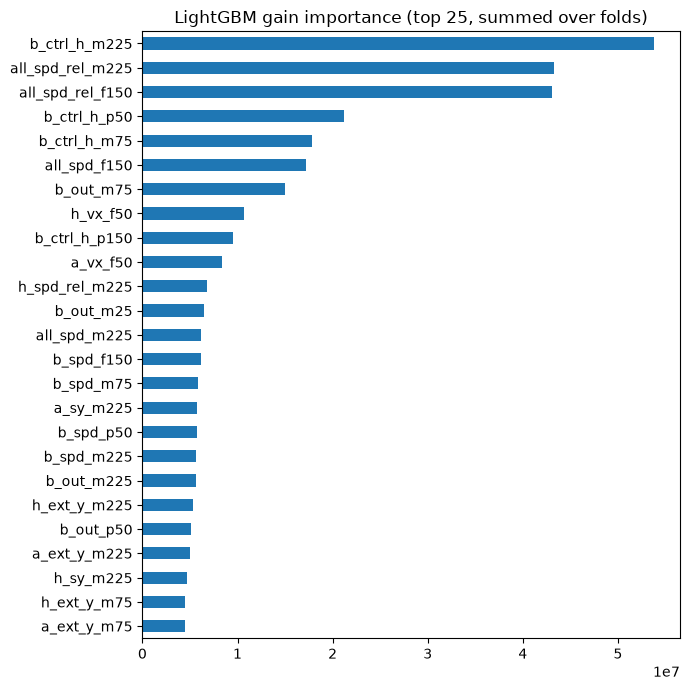

In [24]:
def source_weights(src_arr, share=None):
    share = share or CFG.TRAIN_SHARE
    w = np.ones(len(src_arr), np.float32)
    present = {s: np.mean(src_arr == s) for s in CFG.SOURCES if np.any(src_arr == s)}
    tot = sum(share[s] for s in present)
    for s, frac in present.items():
        w[src_arr == s] = share[s] / tot / frac
    return w

def fit_gbm(mask):
    X = TRAIN_X[mask].astype(np.float32); y = TRAIN_Y[mask]
    w = source_weights(TRAIN_SRC[mask])
    X = np.concatenate([X, swap_X(X, FEATS)]); y = np.concatenate([y, swap_y(y)]); w = np.concatenate([w, w])
    ds = lgb.Dataset(X, y, weight=w, free_raw_data=True)
    del X; gc.collect()
    return lgb.train(CFG.GBM_PARAMS, ds, CFG.GBM_ROUNDS)

def predict_bar(fn):
    return np.concatenate([fn(X_BAR[s:s + 50000]) for s in range(0, len(X_BAR), 50000)]).astype(np.float32)

OOF_GBM, P_BAR['gbm'] = load_oof('gbm')
if OOF_GBM is None:
    OOF_GBM, pbar, imp = {}, np.zeros((len(X_BAR), 3), np.float32), 0
    for fold in range(CFG.N_FOLDS):
        t0 = time.time()
        m = fit_gbm(TRAIN_FOLD != fold)
        for i in VAL_KEYS:
            if HALF_FOLD[i] == fold:
                OOF_GBM[i] = m.predict(VAL_X[i].astype(np.float32)).astype(np.float32)
        pbar += predict_bar(lambda X: m.predict(X.astype(np.float32))) / CFG.N_FOLDS
        imp = imp + m.feature_importance('gain')
        if fold == 0:
            m.save_model(str(CFG.OUT_DIR / 'gbm_fold0.txt'))
        print('fold', fold, '%.0fs' % (time.time() - t0), flush=True)
        del m; gc.collect()
    P_BAR['gbm'] = pbar
    save_oof('gbm', OOF_GBM, pbar)
    pd.Series(imp, index=FEATS).sort_values(ascending=False).to_csv(CFG.EVAL_DIR / 'gbm_feature_importance.csv')
MODEL_REPORT['gbm'] = score_candidate(OOF_GBM, P_BAR['gbm'], **CFG.REF_DECODER)
print(MODEL_REPORT['gbm'])
imp_s = pd.read_csv(CFG.EVAL_DIR / 'gbm_feature_importance.csv', index_col=0).iloc[:, 0]
imp_s.head(25).iloc[::-1].plot.barh(figsize=(7, 7), title='LightGBM gain importance (top 25, summed over folds)')
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'gbm_importance.png', dpi=120); plt.show()

## Sequence Models: BiGRU and TCN, on Two Training Mixtures

Two sequence architectures read 5 fps sequences of the same features in 102 s chunks (512 steps) and label every step, so they can use context the fixed rolling windows cannot, such as how a passing sequence ended. The **BiGRU** is a two-layer bidirectional GRU. The **TCN** is a stack of six residual dilated convolutions (kernel 5, dilations 1 to 32, about 50 s of context on each side) with layer normalisation; it sees the same context through a fixed receptive field instead of a recurrent state, which makes its errors partly independent of the GRU's.

Each architecture is trained on both mixtures (`MIXTURES` A and B). The chunks are built once per fold and shared; only the per-chunk loss weights differ between mixtures. Inputs are robust-scaled with medians and IQRs from the training rows (NaN becomes 0), with Gaussian input noise and the home/away swap as augmentation. Prediction on a 25 fps sequence runs the network on the five 5 fps phases and interleaves the outputs. When a member has several seeds, its fold prediction is the seed average.

In [25]:
class SeqNet(nn.Module):
    def __init__(self, d_in, h):
        super().__init__()
        self.inp = nn.Sequential(nn.Linear(d_in, h), nn.GELU(), nn.Dropout(0.1))
        self.gru = nn.GRU(h, h, num_layers=2, batch_first=True, bidirectional=True, dropout=0.1)
        self.out = nn.Sequential(nn.Dropout(0.1), nn.Linear(2 * h, 3))

    def forward(self, x):
        return self.out(self.gru(self.inp(x))[0])

class TCNNet(nn.Module):
    def __init__(self, d_in, h, dilations, k=5):
        super().__init__()
        self.inp = nn.Sequential(nn.Linear(d_in, h), nn.GELU(), nn.Dropout(0.1))
        self.norms = nn.ModuleList([nn.LayerNorm(h) for _ in dilations])
        self.convs = nn.ModuleList([nn.Sequential(nn.Conv1d(h, h, k, padding=d * (k - 1) // 2, dilation=d), nn.GELU(),
                                                  nn.Dropout(0.1), nn.Conv1d(h, h, 1)) for d in dilations])
        self.out = nn.Sequential(nn.LayerNorm(h), nn.Linear(h, 3))

    def forward(self, x):
        z = self.inp(x)
        for nrm, conv in zip(self.norms, self.convs):
            z = z + conv(nrm(z).transpose(1, 2)).transpose(1, 2)
        return self.out(z)

def make_net(kind, d_in):
    if kind == 'gru':
        return SeqNet(d_in, CFG.GRU_HIDDEN)
    return TCNNet(d_in, CFG.TCN_HIDDEN, CFG.TCN_DILATIONS)

_s = TRAIN_X[::11].astype(np.float32)
SC_MED = np.nanmedian(_s, 0); SC_IQR = np.nanpercentile(_s, 75, 0) - np.nanpercentile(_s, 25, 0) + 1e-3
del _s

def prep(A):
    Z = (A.astype(np.float32) - SC_MED) / SC_IQR
    return np.clip(np.nan_to_num(Z, nan=0.0), -6, 6).astype(np.float16)

SRC_CODE = {s: k for k, s in enumerate(CFG.SOURCES)}

def seq_chunks(mask):
    xs, ys, ss = [], [], []
    L = CFG.GRU_CHUNK
    rows = np.flatnonzero(mask)
    keys = TRAIN_I[rows].astype(np.int64) * 16 + TRAIN_S[rows]
    order = np.lexsort((TRAIN_T[rows], keys))
    rows, keys = rows[order], keys[order]
    bounds = np.flatnonzero(np.diff(keys)) + 1
    for seg in np.split(rows, bounds):
        A = TRAIN_X[seg]; yv = TRAIN_Y[seg]; sc = SRC_CODE[TRAIN_SRC[seg[0]]]
        for swap in (False, True):
            Z = prep(swap_X(A.astype(np.float32), FEATS) if swap else A)
            yy = swap_y(yv) if swap else yv
            for s0 in range(0, len(Z) - 1, L // 2):
                a_, b_ = Z[s0:s0 + L], yy[s0:s0 + L]
                if len(a_) < 64:
                    continue
                pad = L - len(a_)
                xs.append(np.pad(a_, ((0, pad), (0, 0)))); ys.append(np.pad(b_.astype(np.int64), (0, pad), constant_values=-100))
                ss.append(sc)
    return torch.from_numpy(np.stack(xs)), torch.from_numpy(np.stack(ys)), np.array(ss)

def chunk_weights(mask, chunk_src, mix):
    src_rows = TRAIN_SRC[mask]
    w_row = source_weights(src_rows, CFG.MIXTURES[mix])
    per_src = {SRC_CODE[s]: float(w_row[src_rows == s][0]) for s in CFG.SOURCES if np.any(src_rows == s)}
    return torch.tensor([per_src[c] for c in chunk_src], dtype=torch.float32)

def train_seq(kind, Xc, Yc, Wc, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    net = make_net(kind, Xc.shape[-1]).to(CFG.DEVICE)
    steps = CFG.GRU_EPOCHS * ((len(Xc) + CFG.GRU_BATCH - 1) // CFG.GRU_BATCH)
    opt = torch.optim.AdamW(net.parameters(), 2e-3, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, total_steps=steps)
    lossf = nn.CrossEntropyLoss(ignore_index=-100, reduction='none')
    gen = torch.Generator().manual_seed(seed)
    for ep in range(CFG.GRU_EPOCHS):
        net.train(); perm = torch.randperm(len(Xc), generator=gen); tot = 0.0
        for i in range(0, len(Xc), CFG.GRU_BATCH):
            idx = perm[i:i + CFG.GRU_BATCH]
            xb = Xc[idx].to(CFG.DEVICE).float(); yb = Yc[idx].to(CFG.DEVICE); wb = Wc[idx].to(CFG.DEVICE)
            xb = xb + 0.05 * torch.randn(xb.shape, generator=gen).to(CFG.DEVICE)
            tok = lossf(net(xb).reshape(-1, 3), yb.reshape(-1)).reshape(yb.shape)
            valid = (yb != -100).float() * wb[:, None]
            loss = (tok * valid).sum() / valid.sum().clamp_min(1.0)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step(); sched.step()
            tot += loss.item() * len(idx)
    print('  %s seed %d: chunks %d, final epoch loss %.4f' % (kind, seed, len(Xc), tot / len(Xc)), flush=True)
    return net

@torch.no_grad()
def seq_predict(net, X):
    net.eval()
    out = np.zeros((len(X), 3), np.float32)
    for ph in range(5):
        Z = torch.from_numpy(prep(X[ph::5]))[None].to(CFG.DEVICE).float()
        out[ph::5] = torch.softmax(net(Z), -1)[0].cpu().numpy()
    return out

def seq_predict_bar(net):
    out = np.zeros((len(X_BAR), 3), np.float32)
    for s0, s1 in ((0, CFG.HALFTIME_CUT), (CFG.HALFTIME_CUT, len(X_BAR))):
        out[s0:s1] = seq_predict(net, X_BAR[s0:s1])
    return out

The training loop runs over folds on the outside and members on the inside, so each fold's chunks are built once. Members already cached in `cache/oof_<member>.npz` are skipped. Every member is reported with the reference decoder (`REF_DECODER`) together with its decoded BAR-ATH possession rate.

In [26]:
SEQ_NAMES = [f'{k}_{m}' for k, m, _ in CFG.SEQ_MEMBERS]
OOF_SEQ, todo = {}, []
for (kind, mix, n_seed), name in zip(CFG.SEQ_MEMBERS, SEQ_NAMES):
    oof_c, pbar_c = load_oof(name)
    if oof_c is None:
        todo.append((kind, mix, n_seed, name))
    else:
        OOF_SEQ[name], P_BAR[name] = oof_c, pbar_c
if todo:
    acc = {name: ({}, np.zeros((len(X_BAR), 3), np.float32)) for *_, name in todo}
    for fold in range(CFG.N_FOLDS):
        t0 = time.time()
        mask = TRAIN_FOLD != fold
        Xc, Yc, Sc = seq_chunks(mask)
        held = [i for i in VAL_KEYS if HALF_FOLD[i] == fold]
        for kind, mix, n_seed, name in todo:
            Wc = chunk_weights(mask, Sc, mix)
            for sd in range(n_seed):
                net = train_seq(kind, Xc, Yc, Wc, seed=100 * fold + sd)
                for i in held:
                    acc[name][0][i] = acc[name][0].get(i, 0) + seq_predict(net, VAL_X[i]) / n_seed
                acc[name][1][:] += seq_predict_bar(net) / (CFG.N_FOLDS * n_seed)
                del net; torch.cuda.empty_cache()
        print('fold', fold, '%.0fs' % (time.time() - t0), flush=True)
        del Xc, Yc, Sc; gc.collect()
    for kind, mix, n_seed, name in todo:
        OOF_SEQ[name], P_BAR[name] = acc[name][0], acc[name][1]
        save_oof(name, OOF_SEQ[name], P_BAR[name])
for name in SEQ_NAMES:
    MODEL_REPORT[name] = score_candidate(OOF_SEQ[name], P_BAR[name], **CFG.REF_DECODER)
    print(name, {k: round(v, 4) for k, v in MODEL_REPORT[name].items()}, flush=True)
model_tab = pd.DataFrame(MODEL_REPORT).T
model_tab.to_csv(CFG.EVAL_DIR / 'model_oof.csv')
model_tab.round(4)

  gru seed 0: chunks 18362, final epoch loss 0.0774
  gru seed 1: chunks 18362, final epoch loss 0.0781
  gru seed 0: chunks 18362, final epoch loss 0.0626
  tcn seed 0: chunks 18362, final epoch loss 0.0803
  tcn seed 0: chunks 18362, final epoch loss 0.0638
fold 0 1738s
  gru seed 100: chunks 18338, final epoch loss 0.0785
  gru seed 101: chunks 18338, final epoch loss 0.0786
  gru seed 100: chunks 18338, final epoch loss 0.0627
  tcn seed 100: chunks 18338, final epoch loss 0.0827
  tcn seed 100: chunks 18338, final epoch loss 0.0661
fold 1 1764s
  gru seed 200: chunks 18388, final epoch loss 0.0792
  gru seed 201: chunks 18388, final epoch loss 0.0774
  gru seed 200: chunks 18388, final epoch loss 0.0643
  tcn seed 200: chunks 18388, final epoch loss 0.0816
  tcn seed 200: chunks 18388, final epoch loss 0.0657
fold 2 1855s
  gru seed 300: chunks 18812, final epoch loss 0.0756
  gru seed 301: chunks 18812, final epoch loss 0.0761
  gru seed 300: chunks 18812, final epoch loss 0.0615

,dfl_spellF1,metrica_spellF1,pff_spellF1,spellF1,macroF1,dfl_rate_pred,dfl_rate_gt,metrica_rate_pred,metrica_rate_gt,pff_rate_pred,pff_rate_gt,frame_acc,bar_rate,rhythm_penalty,objective
gbm,0.7087,0.7606,0.6327,0.7157,0.9013,4.7464,5.0483,4.0559,4.2943,3.4476,4.1285,0.9003,4.0221,0.0006,0.7151
gru_A,0.7496,0.7985,0.6962,0.7607,0.9184,4.8539,5.0483,4.0598,4.2943,3.3433,4.1285,0.9177,3.9705,0.0019,0.7588
gru_B,0.7186,0.7887,0.6572,0.7383,0.9143,5.1305,5.0483,4.3499,4.2943,3.1916,4.1285,0.9110,3.9597,0.0021,0.7362
tcn_A,0.7073,0.7549,0.6869,0.7260,0.9147,5.4524,5.0483,4.6143,4.2943,3.7342,4.1285,0.9146,4.2198,0.0000,0.7260
tcn_B,0.7046,0.7665,0.6688,0.7266,0.9124,5.3886,5.0483,4.5425,4.2943,3.3982,4.1285,0.9117,4.3296,0.0000,0.7266


#### Insights

> Local runs with LightGBM only (24 PFF matches, one noise draw, every tenth frame, four folds, decoder 12/12), held-out spellF1 per source:

> | training data | DFL | Metrica | PFF |
> |---|---|---|---|
> | DFL only | 0.703 | 0.713 | 0.517 |
> | DFL + PFF | 0.698 | 0.712 | 0.624 |
> | DFL + Metrica | 0.700 | 0.747 | 0.520 |
> | all three, unweighted | 0.699 | 0.744 | 0.624 |
> | all three, Metrica rows x3 | 0.699 | 0.752 | 0.625 |
> | **all three, source shares 35/20/45** | **0.707** | **0.759** | 0.618 |

> Metrica rows are what moves the Metrica halves, and Metrica is the target's tracker and labelling convention. PFF alone does not transfer to the other sources, but with a bounded share it no longer crowds out DFL and Metrica and the combination is the best on both. The PFF gain on PFF halves is in-domain and says little about BAR-ATH.

> The same experiments counted the possessions each model predicts on BAR-ATH: 274 with DFL only, 267 with DFL and Metrica, 217 with DFL and PFF and 224 with the chosen shares. Mixture B gives the sequence models a second view with less PFF and more Metrica, without giving up PFF entirely; the `bar_rate` column of the model table shows how far each member moves.

---

# Ensembling and Sequence Decoding <a name="7"></a>

---

Per-frame probabilities flicker, and spellF1 punishes every flicker twice: an invented possession is a false positive, and the true possession it splits may no longer reach the IoU threshold. The decoder therefore matters as much as the classifier, and every decoder setting below is chosen on the out-of-fold score averaged over the three sources.

## Greedy Ensemble Selection

With five members a full weight grid is too large, so the ensemble is built by forward selection with replacement (Caruana et al., 2004): starting from nothing, each step adds one copy of the member that most improves the objective, and the weights are the copy counts. Every candidate is decoded with the reference decoder, scored on the OOF halves and decoded once on BAR-ATH for the rhythm penalty. The best ensemble along the path is kept (ties go to the earlier, smaller one). A plain 50/50 blend of LightGBM and BiGRU A is scored as a reference row.

In [27]:
OOFS = {'gbm': OOF_GBM, **OOF_SEQ}
names_m = list(OOFS)

def blend_w(wd, key=None):
    tot = float(sum(wd.values()))
    if key is None:
        return sum((c / tot) * P_BAR[n] for n, c in wd.items() if c > 0).astype(np.float32)
    return sum((c / tot) * OOFS[n][key] for n, c in wd.items() if c > 0).astype(np.float32)

_ens_cache = {}

def eval_weights(wd):
    tot = float(sum(wd.values()))
    key = tuple(round(wd.get(m, 0) / tot, 6) for m in names_m)
    if key not in _ens_cache:
        _ens_cache[key] = score_candidate({k: blend_w(wd, k) for k in VAL_KEYS}, blend_w(wd), **CFG.REF_DECODER)
    return _ens_cache[key]

ens_rows, counts = [], {}
for step in range(CFG.ENSEMBLE_STEPS):
    cands = []
    for n in names_m:
        c2 = dict(counts); c2[n] = c2.get(n, 0) + 1
        cands.append((eval_weights(c2)['objective'], n, c2))
    _, n, counts = max(cands, key=lambda x: x[0])
    r = eval_weights(counts)
    w = {m: counts.get(m, 0) / sum(counts.values()) for m in names_m}
    ens_rows.append(dict(step=step + 1, added=n, **r, **{f'w_{m}': w[m] for m in names_m}))
    print('step', step + 1, 'add', n, {k: round(v, 4) for k, v in r.items() if k in ('spellF1', 'bar_rate', 'objective')}, flush=True)
ens_df = pd.DataFrame(ens_rows)
best_row = ens_df.sort_values(['objective', 'step'], ascending=[False, True]).iloc[0]
W_BEST = {m: float(best_row[f'w_{m}']) for m in names_m}
ref_w = {'gbm': 1, SEQ_NAMES[0]: 1}
ref_row = dict(step=0, added='reference: plain blend gbm + ' + SEQ_NAMES[0] + ' 50/50', **eval_weights(ref_w),
               **{f'w_{m}': ref_w.get(m, 0) / 2 for m in names_m})
ens_df = pd.concat([pd.DataFrame([ref_row]), ens_df], ignore_index=True)
ens_df.to_csv(CFG.EVAL_DIR / 'ensemble_selection.csv', index=False)
OOF_ENS = {k: blend_w(W_BEST, k) for k in VAL_KEYS}
P_BAR_ENS = blend_w(W_BEST)
print('chosen weights', {m: round(v, 3) for m, v in W_BEST.items() if v > 0})
cols_show = ['step', 'added', 'spellF1', 'dfl_spellF1', 'metrica_spellF1', 'pff_spellF1', 'bar_rate', 'rhythm_penalty', 'objective']
ens_df[[c for c in cols_show if c in ens_df] + [f'w_{m}' for m in names_m]].round(4)

step 1 add gru_A {'spellF1': 0.7607, 'bar_rate': 3.9705, 'objective': np.float64(0.7588)}
step 2 add tcn_A {'spellF1': 0.7641, 'bar_rate': 4.0308, 'objective': np.float64(0.7638)}
step 3 add tcn_B {'spellF1': 0.7672, 'bar_rate': 4.0906, 'objective': 0.7672}
step 4 add gru_B {'spellF1': 0.7691, 'bar_rate': 4.0283, 'objective': np.float64(0.7687)}
step 5 add tcn_A {'spellF1': 0.7679, 'bar_rate': 4.0799, 'objective': 0.7679}
step 6 add gru_A {'spellF1': 0.7688, 'bar_rate': 4.0794, 'objective': 0.7688}
step 7 add gru_B {'spellF1': 0.7686, 'bar_rate': 4.0334, 'objective': np.float64(0.7683)}
step 8 add tcn_A {'spellF1': 0.7688, 'bar_rate': 4.0629, 'objective': 0.7688}
step 9 add tcn_B {'spellF1': 0.7687, 'bar_rate': 4.0568, 'objective': 0.7687}
step 10 add tcn_B {'spellF1': 0.7691, 'bar_rate': 4.0821, 'objective': 0.7691}
chosen weights {'gru_A': 0.2, 'gru_B': 0.2, 'tcn_A': 0.3, 'tcn_B': 0.3}


,step,added,spellF1,dfl_spellF1,metrica_spellF1,pff_spellF1,bar_rate,rhythm_penalty,objective,w_gbm,w_gru_A,w_gru_B,w_tcn_A,w_tcn_B
0,0,reference: plain blend gbm + gru_A 50/50,0.7601,0.7607,0.7953,0.6889,3.7965,0.0063,0.7537,0.5,0.5000,0.0000,0.0000,0.0000
1,1,gru_A,0.7607,0.7496,0.7985,0.6962,3.9705,0.0019,0.7588,0.0,1.0000,0.0000,0.0000,0.0000
2,2,tcn_A,0.7641,0.7554,0.7970,0.7070,4.0308,0.0004,0.7638,0.0,0.5000,0.0000,0.5000,0.0000
3,3,tcn_B,0.7672,0.7490,0.8065,0.7069,4.0906,0.0000,0.7672,0.0,0.3333,0.0000,0.3333,0.3333
4,4,gru_B,0.7691,0.7524,0.8097,0.7045,4.0283,0.0004,0.7687,0.0,0.2500,0.2500,0.2500,0.2500
5,5,tcn_A,0.7679,0.7508,0.8074,0.7060,4.0799,0.0000,0.7679,0.0,0.2000,0.2000,0.4000,0.2000
6,6,gru_A,0.7688,0.7527,0.8075,0.7075,4.0794,0.0000,0.7688,0.0,0.3333,0.1667,0.3333,0.1667
7,7,gru_B,0.7686,0.7525,0.8083,0.7055,4.0334,0.0003,0.7683,0.0,0.2857,0.2857,0.2857,0.1429
8,8,tcn_A,0.7688,0.7500,0.8091,0.7069,4.0629,0.0000,0.7688,0.0,0.2500,0.2500,0.3750,0.1250
9,9,tcn_B,0.7687,0.7515,0.8089,0.7057,4.0568,0.0000,0.7687,0.0,0.2222,0.2222,0.3333,0.2222


## Decoder: Duration-Constrained Three-State Viterbi

The decoder finds the label sequence maximising the per-frame log-probabilities minus a cost for every switch: `c_team` for a direct `H`/`A` change and `c_dead` for entering or leaving a stoppage. In addition, a stoppage may be required to last at least `min_dead` frames, implemented exactly by expanding `D` into a chain of `min_dead` sub-states (a semi-Markov minimum duration). The grid now starts at `c_team = 2` so that the rhythm term has room to act; all settings are ranked by the same objective as the ensemble.

$$\hat{y} = \arg\max_{y_{1:T}} \sum_t \log p(y_t \mid x) - \sum_t c(y_{t-1}, y_t) \quad \text{s.t. every } D \text{ run} \ge \texttt{min\_dead}$$

In [28]:
dec_rows = []
for ct, cd in itertools.product(CFG.DECODER_GRID['c_team'], CFG.DECODER_GRID['c_dead']):
    r = score_candidate(OOF_ENS, P_BAR_ENS, c_team=ct, c_dead=cd); r.update(c_team=ct, c_dead=cd, min_dead=1)
    dec_rows.append(r)
    print({k: round(v, 4) for k, v in r.items() if k in ('c_team', 'c_dead', 'spellF1', 'bar_rate', 'objective')}, flush=True)
dec_df = pd.DataFrame(dec_rows).sort_values('objective', ascending=False)
C_TEAM, C_DEAD = float(dec_df.iloc[0].c_team), float(dec_df.iloc[0].c_dead)
dur_rows = []
for md_ in CFG.MIN_DEAD_GRID:
    r = score_candidate(OOF_ENS, P_BAR_ENS, c_team=C_TEAM, c_dead=C_DEAD, min_dead=md_)
    r.update(c_team=C_TEAM, c_dead=C_DEAD, min_dead=md_)
    dur_rows.append(r)
dur_df = pd.DataFrame(dur_rows).sort_values('objective', ascending=False)
MIN_DEAD = int(dur_df.iloc[0].min_dead)
pd.concat([dec_df, dur_df]).to_csv(CFG.EVAL_DIR / 'decoder_grid.csv', index=False)
raw = oof_score(OOF_ENS, c_team=0.0, c_dead=0.0)
print('decoder chosen: c_team', C_TEAM, 'c_dead', C_DEAD, 'min_dead', MIN_DEAD)
print('per-frame argmax (no decoding):', {k: round(v, 4) for k, v in raw.items() if 'rate' not in k})
dur_df[[c for c in ('c_team', 'c_dead', 'min_dead', 'spellF1', 'dfl_spellF1', 'metrica_spellF1', 'pff_spellF1', 'bar_rate', 'objective')
        if c in dur_df]].round(4)

{'spellF1': 0.7549, 'bar_rate': 4.3888, 'objective': 0.7549, 'c_team': 2, 'c_dead': 6}
{'spellF1': 0.7543, 'bar_rate': 4.3372, 'objective': 0.7543, 'c_team': 2, 'c_dead': 8}
{'spellF1': 0.7536, 'bar_rate': 4.231, 'objective': 0.7536, 'c_team': 2, 'c_dead': 12}
{'spellF1': 0.7537, 'bar_rate': 4.2091, 'objective': 0.7537, 'c_team': 2, 'c_dead': 16}
{'spellF1': 0.753, 'bar_rate': 4.1246, 'objective': 0.753, 'c_team': 2, 'c_dead': 24}
{'spellF1': 0.7627, 'bar_rate': 4.3703, 'objective': 0.7627, 'c_team': 4, 'c_dead': 6}
{'spellF1': 0.7619, 'bar_rate': 4.3186, 'objective': 0.7619, 'c_team': 4, 'c_dead': 8}
{'spellF1': 0.7614, 'bar_rate': 4.2124, 'objective': 0.7614, 'c_team': 4, 'c_dead': 12}
{'spellF1': 0.7615, 'bar_rate': 4.1906, 'objective': 0.7615, 'c_team': 4, 'c_dead': 16}
{'spellF1': 0.7614, 'bar_rate': 4.1061, 'objective': 0.7614, 'c_team': 4, 'c_dead': 24}
{'spellF1': 0.7657, 'bar_rate': 4.3703, 'objective': 0.7657, 'c_team': 6, 'c_dead': 6}
{'spellF1': 0.765, 'bar_rate': 4.3186, '

,c_team,c_dead,min_dead,spellF1,dfl_spellF1,metrica_spellF1,pff_spellF1,bar_rate,objective
1,12.0,6.0,50,0.7706,0.7501,0.8138,0.7046,4.2404,0.7706
0,12.0,6.0,1,0.7705,0.7505,0.8135,0.7045,4.2410,0.7705


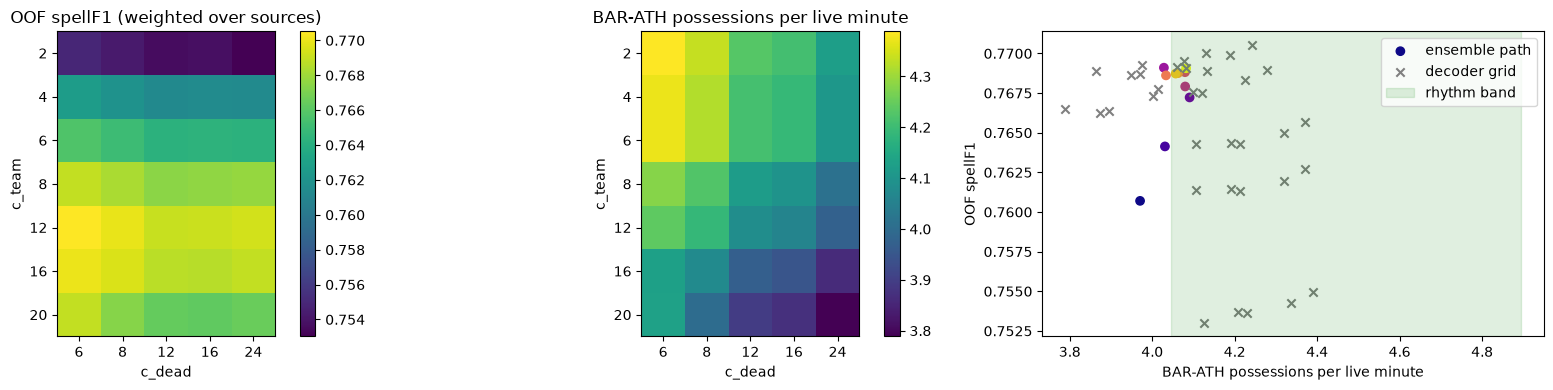

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for j, (col, title) in enumerate((('spellF1', 'OOF spellF1 (weighted over sources)'),
                                  ('bar_rate', 'BAR-ATH possessions per live minute'))):
    pivot = dec_df.pivot(index='c_team', columns='c_dead', values=col)
    im = ax[j].imshow(pivot.values, cmap='viridis'); ax[j].set_title(title)
    ax[j].set_xticks(range(len(pivot.columns))); ax[j].set_xticklabels(pivot.columns); ax[j].set_xlabel('c_dead')
    ax[j].set_yticks(range(len(pivot.index))); ax[j].set_yticklabels(pivot.index); ax[j].set_ylabel('c_team')
    plt.colorbar(im, ax=ax[j])
cur = ens_df[ens_df.step > 0]
ax[2].scatter(cur.bar_rate, cur.spellF1, c=cur.step, cmap='plasma', label='ensemble path')
ax[2].scatter(dec_df.bar_rate, dec_df.spellF1, marker='x', color='grey', label='decoder grid')
ax[2].axvspan(RHYTHM_LOW, RHYTHM_HIGH, color='green', alpha=0.12, label='rhythm band')
ax[2].set_xlabel('BAR-ATH possessions per live minute'); ax[2].set_ylabel('OOF spellF1'); ax[2].legend()
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'decoder_grid.png', dpi=120); plt.show()

## Rhythm on Held-Out Halves

If the ensemble under-segments the held-out halves as well, the cause is in the training labels or the selection, not in the shift from external tracking to BAR-ATH. The table compares predicted and labelled possessions per live minute on the held-out halves of each source (labels at the first `EVAL_TAU` value), next to BAR-ATH and the reference.

In [30]:
DEC_KW = dict(c_team=C_TEAM, c_dead=C_DEAD, min_dead=MIN_DEAD)
fin_ = score_candidate(OOF_ENS, P_BAR_ENS, **DEC_KW)
rhythm_rows = [dict(source=s, predicted=fin_[f'{s}_rate_pred'], labelled=fin_[f'{s}_rate_gt']) for s in CFG.SOURCES
               if f'{s}_rate_pred' in fin_]
rhythm_rows.append(dict(source='BAR-ATH (model only)', predicted=fin_['bar_rate'], labelled=np.nan))
rhythm_rows.append(dict(source='reference band', predicted=np.nan, labelled=RHYTHM_TARGET))
rhythm_df = pd.DataFrame(rhythm_rows)
rhythm_df['ratio'] = rhythm_df.predicted / rhythm_df.labelled
rhythm_df.to_csv(CFG.EVAL_DIR / 'rhythm.csv', index=False)
rhythm_df.round(3)

,source,predicted,labelled,ratio
0,dfl,4.964,5.048,0.983
1,metrica,4.136,4.294,0.963
2,pff,3.313,4.129,0.803
3,BAR-ATH (model only),4.240,NaN,NaN
4,reference band,NaN,4.449,NaN


## Boundary Timing

The metric is very sensitive to where boundaries fall (a systematic 1 s offset costs about 0.35 spellF1 on a typical possession). For every true transition the nearest predicted transition of the same kind is found within 10 s, and the signed offset (prediction minus truth, in frames) is summarised per transition kind and source. The public window is shown for comparison only.

In [31]:
def transitions(lab):
    d = np.flatnonzero(lab[1:] != lab[:-1]) + 1
    return [(int(t), int(lab[t - 1]), int(lab[t])) for t in d if lab[t - 1] < 3 and lab[t] < 3]

def boundary_offsets(gt, pred, window=250):
    by = {}
    for t, a_, b_ in transitions(pred):
        by.setdefault((a_, b_), []).append(t)
    out = []
    for t, a_, b_ in transitions(gt):
        kind = 'team' if (a_ < 2 and b_ < 2) else ('enter_D' if b_ == 2 else 'leave_D')
        arr = np.array(by.get((a_, b_), []))
        if len(arr) == 0:
            out.append((kind, np.nan)); continue
        off = arr[np.argmin(np.abs(arr - t))] - t
        out.append((kind, off if abs(off) <= window else np.nan))
    return out

DEC_KW = dict(c_team=C_TEAM, c_dead=C_DEAD, min_dead=MIN_DEAD)
off_rows = []
for i in VAL_KEYS:
    pred = decode(OOF_ENS[i], [(0, len(OOF_ENS[i]))], **DEC_KW)
    g = next(iter(VAL_GT[i].values()))
    off_rows += [(VAL_SRC[i], k, o) for k, o in boundary_offsets(g, pred)]
pred_pub = decode(P_BAR_ENS, CFG.HALVES, **DEC_KW)
a, b = CFG.PUBLIC
off_rows += [('BAR public', k, o) for k, o in boundary_offsets(gt_pub[a:b], pred_pub[a:b])]
off_df = pd.DataFrame(off_rows, columns=['source', 'kind', 'offset'])
off_tab = off_df.groupby(['source', 'kind']).offset.agg(
    n='size', matched='count', median='median', mean='mean',
    q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75)).round(1)
off_tab.to_csv(CFG.EVAL_DIR / 'boundary_offsets.csv')
off_tab

n  matched  median  mean   q25   q75
source     kind                                            
BAR public enter_D     4        2    15.0  15.0  11.5  18.5
           leave_D     4        3     5.0  12.3  -4.5  25.5
           team       12        7     2.0  18.1   0.5  37.0
dfl        enter_D   710      568    -1.0  -1.9  -8.0   5.0
           leave_D   699      653     0.0  -2.6  -2.0   2.0
           team     1318     1054    -0.5  -3.2 -16.0  13.8
metrica    enter_D   304      250     1.0   5.7  -4.0  16.8
           leave_D   298      269     0.0   1.0  -2.0   3.0
           team      494      401     1.0   2.0  -8.0  11.0
pff        enter_D  1554     1155    -1.0  -3.8 -17.0  14.0
           leave_D  1543     1316    -2.0  -0.9 -18.0  15.0
           team     2632     1717    -1.0  -1.0 -23.0  19.0

#### Insights

> The decoder surface is flat near the optimum: the ten best settings lie within 0.003 OOF spellF1 of each other, so the rhythm term acts as the tie-break. The decoder by itself moves the possession rate little, so most of the rhythm comes from the ensemble members, and the chosen ensemble keeps BAR-ATH inside the reference band (4.24 possessions per live minute before the evidence terms).

> Boundary timing is essentially unbiased on DFL and PFF (median offsets within 4 frames). On Metrica, entering a stoppage is predicted about 9 frames late and team changes about 8 frames late, both well below the size at which a systematic shift would pay off (3 frames cost about 0.02), so no boundary shift is applied. The 1 to 2 s delays seen on the public window come from four stoppages and are not reproduced on the 300 held-out Metrica stoppages.

> The minimum-stoppage constraint (2 s) is selected and agrees with football: real stoppages are almost never shorter than that. Its effect on the OOF score is small because the switch costs already suppress very short false stoppages.

---

# Match-Specific Evidence <a name="8"></a>

---

Two signals exist only for this match and are added to the decoder as explicit log-likelihood terms on `D`: the broadcast replay flag and the pattern of missing-ball gaps in the tactical tracking. Neither can be validated on the external data, and the public window holds only four stoppages, so each term is checked against the other: the missing-ball term is estimated without the replay flag, and the replay flag then serves as an independent referee over the whole match.

## Broadcast Replay as Dead-Ball Evidence

Under a naive-Bayes view, the replay flag contributes `log P(flag | D) - log P(flag | alive)` to the dead-ball state. On the public window those log-ratios are about +3.1 (replay) and -1.4 (live picture); half of each (`REPLAY_WEIGHTS`) is used, to avoid over-trusting four dead-ball stretches.

In [32]:
def replay_logp(w_replay, w_live):
    e = np.zeros((CFG.N_FRAMES, 3))
    e[:, 2] = np.where(replay == 1, w_replay, np.where(replay == 0, w_live, 0.0))
    return e

REPLAY_TERM = replay_logp(*CFG.REPLAY_WEIGHTS)

## Missing-Ball Gaps as Dead-Ball Evidence

The frame models were trained with ball gaps copied independently of the label, so their posterior is close to blind to whether a gap means a stoppage. That makes it a valid second view for one expectation-maximisation step: each graded frame gets a gap category (ball present, or the length of the gap it sits in, from under 0.5 s to over 30 s), and the dead-ball posterior `q` from the model-only decode weights the counts, giving `log P(category | D) - log P(category | alive)`. The term enters the decoder with weight `MISS_SHRINK`.

The check uses the replay flag, which is not used in this estimate: if the missing-ball term moves the decoded stoppages towards the truth, the decoded `D` frames should agree better with the replay flag. Agreement is measured as the average log-likelihood of the replay flag under the public-window rates `P(replay | D) = 0.76`, `P(replay | alive) = 0.034`, and the term is kept only if it raises that likelihood.

In [33]:
miss = np.isnan(B_merged[:, 0])
gap_frames = np.where(miss, run_since(~miss) + run_since(~miss[::-1])[::-1] - 1, 0)
GAP_EDGES = [1, 13, 51, 126, 251, 751]
gap_cat = np.where(miss, np.digitize(gap_frames, GAP_EDGES[1:]) + 1, 0)
N_CAT = len(GAP_EDGES) + 1

def miss_logratio(q_dead, alpha=50.0):
    m = graded
    prior = np.bincount(gap_cat[m], minlength=N_CAT) / m.sum()
    cD = np.bincount(gap_cat[m], weights=q_dead[m], minlength=N_CAT) + alpha * prior
    cA = np.bincount(gap_cat[m], weights=1 - q_dead[m], minlength=N_CAT) + alpha * prior
    return np.log(cD / cD.sum()) - np.log(cA / cA.sum())

def gap_term(lr, w):
    e = np.zeros((CFG.N_FRAMES, 3)); e[:, 2] = w * lr[gap_cat]
    return e

def replay_agreement(pred):
    m = graded & ~np.isnan(replay)
    d = pred[m] == 2; r = replay[m] == 1
    pr = np.where(d, 0.756, 0.034)
    tp = np.sum(d & r)
    f1 = 2 * tp / max(d.sum() + r.sum(), 1)
    return float(np.mean(np.where(r, np.log(pr), np.log(1 - pr)))), float(f1)

def full_stats(pred):
    st = pm.possession_stats(pred, CFG.HALVES)
    return dict(possessions=st['n_spells'], rate_per_live_min=bar_rate(pred), dead_share=float(np.mean(pred[graded] == 2)),
                stoppages=sum(1 for s in pm.segments(pred, CFG.HALVES) if s[2] == 2))

base = decode(P_BAR_ENS, CFG.HALVES, **DEC_KW)
q_dead = 0.5 * P_BAR_ENS[:, 2] + 0.5 * (base == 2)
MISS_LR = miss_logratio(q_dead)
ev_rows = []
for name, extra in (('model only', None), ('+ gap term x0.5', gap_term(MISS_LR, 0.5)), ('+ gap term x1', gap_term(MISS_LR, 1.0))):
    pred = decode(P_BAR_ENS, CFG.HALVES, extra_logp=extra, **DEC_KW)
    ll, f1 = replay_agreement(pred)
    ev_rows.append(dict(variant=name, replay_loglik=ll, replay_f1=f1, **full_stats(pred),
                        **{'public_' + k: v for k, v in public_score(pred).items()}))
for name, extra in (('replay term', REPLAY_TERM), ('replay + gap x0.5', REPLAY_TERM + gap_term(MISS_LR, 0.5)),
                    ('replay + gap x1', REPLAY_TERM + gap_term(MISS_LR, 1.0))):
    pred = decode(P_BAR_ENS, CFG.HALVES, extra_logp=extra, **DEC_KW)
    ev_rows.append(dict(variant=name, **full_stats(pred), **{'public_' + k: v for k, v in public_score(pred).items()}))
ev_df = pd.DataFrame(ev_rows)
ev_df.to_csv(CFG.EVAL_DIR / 'match_evidence.csv', index=False)
USE_GAP = ev_df.set_index('variant').loc[f'+ gap term x{CFG.MISS_SHRINK:g}', 'replay_loglik'] > ev_df.set_index('variant').loc['model only', 'replay_loglik']
EXTRA = REPLAY_TERM + (gap_term(MISS_LR, CFG.MISS_SHRINK) if USE_GAP else 0)
print('gap-category log-ratios (present, <0.5s, 0.5-2s, 2-5s, 5-10s, 10-30s, >30s):', np.round(MISS_LR, 2))
print('gap term kept:', bool(USE_GAP))
ev_df.round(4)

gap-category log-ratios (present, <0.5s, 0.5-2s, 2-5s, 5-10s, 10-30s, >30s): [-0.99  1.7   2.16  2.45  1.13  2.22  4.33]
gap term kept: True


,variant,replay_loglik,replay_f1,possessions,rate_per_live_min,dead_share,stoppages,public_spellF1,public_macroF1,public_n_pred,public_n_gt
0,model only,-0.4648,0.7349,225,4.2404,0.4990,121,0.7515,0.8790,16,17
1,+ gap term x0.5,-0.4588,0.7387,218,4.0793,0.4954,117,0.7097,0.9103,14,17
2,+ gap term x1,-0.4565,0.7398,219,4.1019,0.4959,120,0.7097,0.9340,14,17
3,replay term,NaN,NaN,221,4.0871,0.4894,115,0.6875,0.9191,15,17
4,replay + gap x0.5,NaN,NaN,216,3.9813,0.4877,109,0.6875,0.9267,15,17
5,replay + gap x1,NaN,NaN,216,3.9967,0.4897,111,0.6875,0.9268,15,17


#### Insights

> The EM step gives the expected shape: a visible ball argues for live play (log-ratio about -1), short flickers mildly for a stoppage, and gaps longer than 10 s strongly for one (+2 to +3.5). On this run the term at weight 0.5 raises the replay log-likelihood from -0.465 to -0.459, so the gate keeps it, at the conservative half weight fixed in advance.

> Both terms change only a handful of stoppages over the match. The public window cannot rank them (four stoppages), so the decision rests on the replay cross-check for the gap term and on the public-window likelihood ratios for the replay term.

---

# Final Submission <a name="9"></a>

---

The final labels decode the ensemble probabilities with the chosen decoder and the evidence terms. Graded frames get `H`, `A` or `D`; ungraded frames get `X`, which is never scored. The file is validated with the official checker and scored on the public window with the official script.

In [34]:
FINAL = decode(P_BAR_ENS, CFG.HALVES, extra_logp=EXTRA, **DEC_KW)
labels = np.array(list('HADX'))[FINAL]
sub = pd.DataFrame({'frame': np.arange(CFG.N_FRAMES), 'label': labels})
SUB_PATH = CFG.OUT_DIR / f'{CFG.TEAM_NAME}.csv'
sub.to_csv(SUB_PATH, index=False, lineterminator='\n')
err = pm.validate_submission(pm.read_label_csv(SUB_PATH), CFG.N_FRAMES)
print('validation:', 'OK' if err is None else err)
print(sub.label.value_counts().to_dict())

validation: OK
{'D': 77477, 'H': 51631, 'X': 40462, 'A': 29749}


## Reproducibility Bundle

The repository must regenerate the identical file. GPU training is not guaranteed to be bit-exact across hardware, so the notebook saves the inputs of the last, deterministic step: the ensemble probabilities (`final_probabilities.npy`, float32), the evidence term on `D` (`decoder_evidence.npy`) and the decoder settings (`decoder.json`). The stand-alone `regenerate_submission.py` written below rebuilds the CSV from these three files with the same duration-constrained Viterbi, and the cell checks that its output is byte-identical to the submission.

In [35]:
np.save(CFG.OUT_DIR / 'final_probabilities.npy', P_BAR_ENS.astype(np.float32))
np.save(CFG.OUT_DIR / 'decoder_evidence.npy', np.asarray(EXTRA, np.float64)[:, 2].astype(np.float32))
EXTRA = np.zeros((CFG.N_FRAMES, 3)); EXTRA[:, 2] = np.load(CFG.OUT_DIR / 'decoder_evidence.npy').astype(np.float64)
FINAL = decode(np.load(CFG.OUT_DIR / 'final_probabilities.npy'), CFG.HALVES, extra_logp=EXTRA, **DEC_KW)
pd.DataFrame({'frame': np.arange(CFG.N_FRAMES), 'label': np.array(list('HADX'))[FINAL]}).to_csv(SUB_PATH, index=False, lineterminator='\n')
json.dump(dict(DEC_KW, halves=CFG.HALVES, n_frames=CFG.N_FRAMES, team_name=CFG.TEAM_NAME),
          open(CFG.OUT_DIR / 'decoder.json', 'w'), indent=1)

REGEN = """import json, sys
from pathlib import Path
import numpy as np
from numba import njit

@njit(cache=True)
def viterbi_dur(lp, cost, kmin):
    T = lp.shape[0]
    off = np.zeros(4, np.int64)
    for k in range(3):
        off[k + 1] = off[k] + kmin[k]
    S = off[3]
    lab = np.zeros(S, np.int64)
    for k in range(3):
        for i in range(kmin[k]):
            lab[off[k] + i] = k
    NEG = -1e18
    sc = np.full(S, NEG)
    for k in range(3):
        sc[off[k]] = lp[0, k]
    back = np.zeros((T, S), np.int32)
    new = np.empty(S)
    for t in range(1, T):
        for j in range(3):
            best = NEG; bi = -1
            for i in range(3):
                if i == j:
                    continue
                v = sc[off[i + 1] - 1] - cost[i, j]
                if v > best:
                    best = v; bi = off[i + 1] - 1
            if kmin[j] == 1:
                if sc[off[j]] >= best:
                    best = sc[off[j]]; bi = off[j]
            new[off[j]] = best + lp[t, j]
            back[t, off[j]] = bi
            for s in range(1, kmin[j]):
                st = off[j] + s
                if s == kmin[j] - 1 and sc[st] > sc[st - 1]:
                    new[st] = sc[st] + lp[t, j]; back[t, st] = st
                else:
                    new[st] = sc[st - 1] + lp[t, j]; back[t, st] = st - 1
        for s in range(S):
            sc[s] = new[s]
    bs = 0
    for s in range(S):
        if sc[s] > sc[bs]:
            bs = s
    path = np.zeros(T, np.int8)
    s = bs
    for t in range(T - 1, -1, -1):
        path[t] = lab[s]
        if t > 0:
            s = back[t, s]
    return path

d = Path(sys.argv[1]) if len(sys.argv) > 1 else Path(__file__).parent
cfg = json.load(open(d / 'decoder.json'))
prob = np.load(d / 'final_probabilities.npy').astype(np.float64)
lp = np.log(np.clip(prob, 1e-4, 1.0))
lp[:, 2] += np.load(d / 'decoder_evidence.npy').astype(np.float64)
ct, cd = cfg['c_team'], cfg['c_dead']
cost = np.array([[0, ct, cd], [ct, 0, cd], [cd, cd, 0]], np.float64)
kmin = np.array([1, 1, cfg['min_dead']], np.int64)
out = np.full(cfg['n_frames'], 3, np.int8)
for s, e in cfg['halves']:
    out[s:e] = viterbi_dur(np.ascontiguousarray(lp[s:e]), cost, kmin)
labels = np.array(list('HADX'))[out]
with open(d / (cfg['team_name'] + '_regenerated.csv'), 'w', newline='\\n') as f:
    f.write('frame,label\\n')
    f.write(''.join(f'{i},{l}\\n' for i, l in enumerate(labels)))
print('wrote', d / (cfg['team_name'] + '_regenerated.csv'))
"""
(CFG.OUT_DIR / 'regenerate_submission.py').write_text(REGEN)
r = subprocess.run([sys.executable, str(CFG.OUT_DIR / 'regenerate_submission.py'), str(CFG.OUT_DIR)], capture_output=True, text=True)
print(r.stdout, r.stderr[-500:])
same = (CFG.OUT_DIR / f'{CFG.TEAM_NAME}_regenerated.csv').read_bytes() == SUB_PATH.read_bytes()
print('regenerated file byte-identical to the submission:', same)

wrote /mtah_work/outputs/False_Five_regenerated.csv
 
regenerated file byte-identical to the submission: True


In [36]:
shutil.copy(SUB_PATH, CFG.REPO_DIR / 'evaluation' / 'results' / SUB_PATH.name)
r = subprocess.run([sys.executable, str(CFG.REPO_DIR / 'evaluation' / 'validate_submission.py'), str(SUB_PATH)], capture_output=True, text=True)
print(r.stdout[-1500:], r.stderr[-800:])
r = subprocess.run([sys.executable, str(CFG.REPO_DIR / 'evaluation' / 'run_evaluation.py'), '--bootstrap', '1000'],
                   capture_output=True, text=True, cwd=str(CFG.REPO_DIR))
print(r.stdout[-5000:], r.stderr[-800:])
(CFG.EVAL_DIR / 'official_scoreboard_public.txt').write_text(r.stdout)

OK    False_Five.csv
      199319 rows, frame 0..199318

      label counts
        H    51631   25.9%
        A    29749   14.9%
        D    77477   38.9%
        X    40462   20.3%

      reports 216 possessions of mean 15.1 s
      (counted with each X as a gap; the scorer bridges abstentions inside a real
       possession, so its count can be lower than this one)

Valid. Note this checks the format only -- it says nothing about whether the labels are right.
Score it against the public ground truth with run_evaluation.py.
 
 spurious 9
  alive/dead F1 0.8991   team acc  gt-alive 0.8854  both-alive 0.8854
  share        gt home 0.5727  pred 0.6247  err 0.0520
  fragmentation  17 / 21 = 0.81
  abstained    0 frames of X on graded ground truth (0.00%)

baseline_smooth50
  macro F1 0.6207  (H 0.7781  A 0.7615  D 0.3225)   kappa 0.5202  acc 0.7132
  bootstrap macroF1 5-95 pct  0.4602 .. 0.7418   (21 segments, 1000 draws)
  per class          precision   recall       F1   support
    H 

9253

---

# Evaluation Report and Error Analysis <a name="10"></a>

---

Everything needed to judge and iterate on the submission is written to `outputs/evaluation/`: per-model OOF scores, ensemble and decoder grids, per-half OOF scores, boundary offsets, the evidence table, public-window metrics with a per-IoU breakdown and a segment-level comparison, and full-match statistics.

In [37]:
final_oof, half_df = oof_score(OOF_ENS, detail=True, **DEC_KW)
half_df['match'] = [Path(HALF_KEYS[i][1]).stem for i in half_df.half]
half_df['period'] = [HALF_KEYS[i][2] for i in half_df.half]
half_df.to_csv(CFG.EVAL_DIR / 'oof_per_half.csv', index=False)

g = np.full(CFG.N_FRAMES, 3, np.int8); a, b = CFG.PUBLIC; g[a:b] = gt_pub[a:b]
p = np.full(CFG.N_FRAMES, 3, np.int8); p[a:b] = FINAL[a:b]
pub = pm.evaluate(g, p, bootstrap_n=1000)
report = dict(
    oof=dict(final_oof, spellF1_std_over_halves=float(half_df.spellF1.std())),
    public=dict(spellF1=pub['spell_f1_mean'], spellF1_ci=[pub['spell_bootstrap_low'], pub['spell_bootstrap_high']],
                macroF1=pub['macro_f1'], per_iou={str(k): v['f1'] for k, v in pub['spell_f1'].items()},
                n_pred=pub['n_pred_spells'], n_gt=pub['n_gt_spells'], alive_dead_f1=pub['alive_dead_f1']),
    full_match=dict(full_stats(FINAL), mean_possession_s=pm.possession_stats(FINAL, CFG.HALVES)['mean_duration_s'],
                    barcelona_share=pm.possession_stats(FINAL, CFG.HALVES)['home_share']),
    models=MODEL_REPORT, ensemble_weights={m: float(v) for m, v in W_BEST.items()},
    decoder=dict(DEC_KW, replay_weights=CFG.REPLAY_WEIGHTS, gap_term=bool(USE_GAP), gap_shrink=CFG.MISS_SHRINK,
                 gap_logratios=[float(x) for x in MISS_LR]),
    rhythm=dict(reference=RHYTHM_TARGET, band=[RHYTHM_LOW, RHYTHM_HIGH], bar_final=bar_rate(FINAL),
                bar_model_only=fin_['bar_rate'], oof={r['source']: [r['predicted'], r['labelled']] for r in rhythm_rows[:-2]},
                mixtures=CFG.MIXTURES, members=[list(m) for m in CFG.SEQ_MEMBERS]),
    data=dict(halves={s: int((HALF_SRC == s).sum()) for s in CFG.SOURCES}, validation_halves=len(VAL_KEYS),
              training_rows=int(len(TRAIN_Y))),
    eda=EDA)
with open(CFG.EVAL_DIR / 'report.json', 'w') as f:
    json.dump(report, f, indent=1, default=float)
print(json.dumps({k: report[k] for k in ('oof', 'public', 'full_match', 'decoder', 'rhythm', 'ensemble_weights')}, indent=1, default=float))

{
 "oof": {
  "dfl_spellF1": 0.7500953483038296,
  "metrica_spellF1": 0.8137838816490802,
  "pff_spellF1": 0.7045550052577128,
  "spellF1": 0.7705545292149256,
  "macroF1": 0.9225552175602746,
  "dfl_rate_pred": 4.964454073356341,
  "dfl_rate_gt": 5.048318131277063,
  "metrica_rate_pred": 4.136283920989477,
  "metrica_rate_gt": 4.2943325555692,
  "pff_rate_pred": 3.3134941892265273,
  "pff_rate_gt": 4.12854449495873,
  "frame_acc": 0.9215390152114805,
  "spellF1_std_over_halves": 0.059526397874778494
 },
 "public": {
  "spellF1": 0.6875,
  "spellF1_ci": [
   0.5125,
   0.8625
  ],
  "macroF1": 0.9267340306088325,
  "per_iou": {
   "0.3": 0.8125,
   "0.4": 0.6875,
   "0.5": 0.6875,
   "0.6": 0.625,
   "0.7": 0.625
  },
  "n_pred": 15,
  "n_gt": 17,
  "alive_dead_f1": 0.9787059787059788
 },
 "full_match": {
  "possessions": 216,
  "rate_per_live_min": 3.981322192184812,
  "dead_share": 0.4877153666505096,
  "stoppages": 109,
  "mean_possession_s": 15.07037037037037,
  "barcelona_share": 

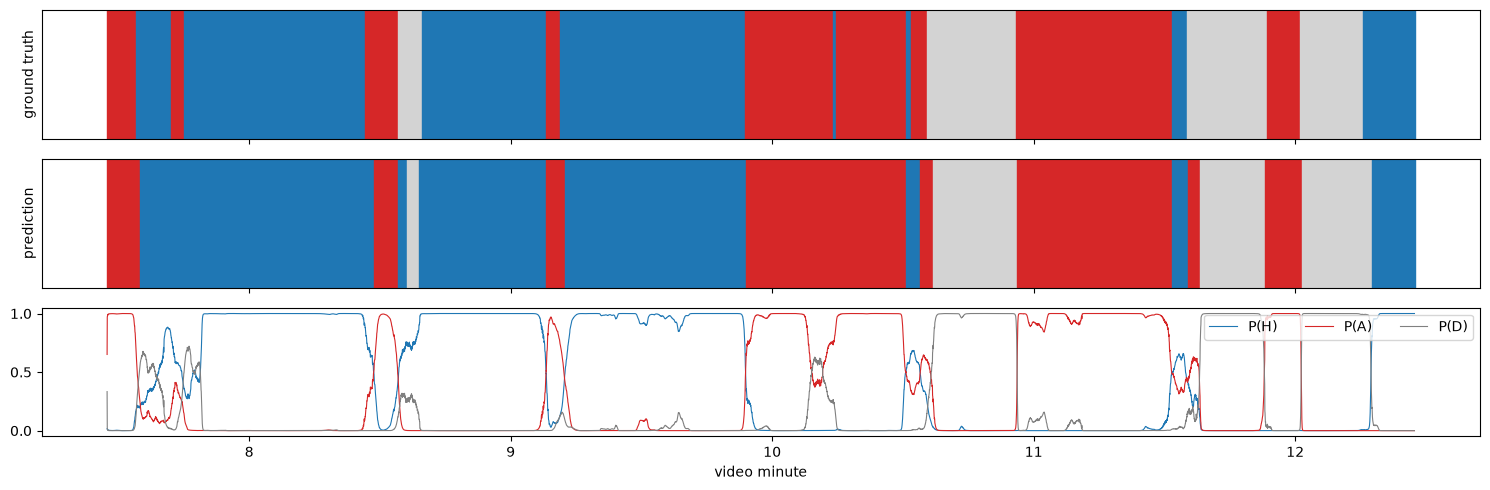

,gt_start,gt_end,gt,seconds,best_pred,pred_start,pred_end,iou_same_label,ball_present
0,11185,11351,A,6.64,A,11185,11376,0.869,0.987952
1,11351,11553,H,8.08,H,11376,12715,0.130,0.975248
2,11553,11624,A,2.84,H,11376,12715,0.000,1.000000
3,11624,12665,H,41.64,H,11376,12715,0.777,1.000000
4,12665,12851,A,7.44,A,12715,12855,0.716,0.892473
5,12851,12989,D,5.52,D,12907,12974,0.486,0.072464
6,12989,13704,H,28.60,H,12974,13703,0.978,1.000000
7,13704,13785,A,3.24,A,13703,13809,0.764,1.000000
8,13785,14846,H,42.44,H,13809,14848,0.976,1.000000
9,14846,15346,A,20.00,A,14848,15768,0.540,1.000000


In [38]:
gs = pm.segments(g, [(a, b)]); ps = pm.segments(p, [(a, b)])
rows = []
for s, e, k in gs:
    ov = [(min(e, pe) - max(s, ps_), 'HADX'[pk], ps_, pe) for ps_, pe, pk in ps if pe > s and ps_ < e]
    best = max(ov) if ov else (0, '-', 0, 0)
    iou = best[0] / (max(e, best[3]) - min(s, best[2])) if best[1] == 'HADX'[k] else 0.0
    rows.append(dict(gt_start=s, gt_end=e, gt='HADX'[k], seconds=(e - s) / 25, best_pred=best[1], pred_start=best[2],
                     pred_end=best[3], iou_same_label=round(iou, 3), ball_present=float(ball_ok[s:e].mean())))
err_df = pd.DataFrame(rows); err_df.to_csv(CFG.EVAL_DIR / 'public_segment_errors.csv', index=False)

fig, ax = plt.subplots(3, 1, figsize=(15, 5), sharex=True)
cmap = {0: 'tab:blue', 1: 'tab:red', 2: 'lightgrey'}
for row, (arr, title) in enumerate([(g, 'ground truth'), (p, 'prediction')]):
    for s, e, k in pm.segments(arr, [(a, b)]):
        ax[row].axvspan(s / 1500, e / 1500, color=cmap[k])
    ax[row].set_yticks([]); ax[row].set_ylabel(title)
t = np.arange(a, b)
for k, (col, lab_) in enumerate(zip(('tab:blue', 'tab:red', 'grey'), ('P(H)', 'P(A)', 'P(D)'))):
    ax[2].plot(t / 1500, P_BAR_ENS[a:b, k], color=col, lw=0.8, label=lab_)
ax[2].legend(loc='upper right', ncol=3); ax[2].set_xlabel('video minute')
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'public_window_timeline.png', dpi=120); plt.show()
err_df

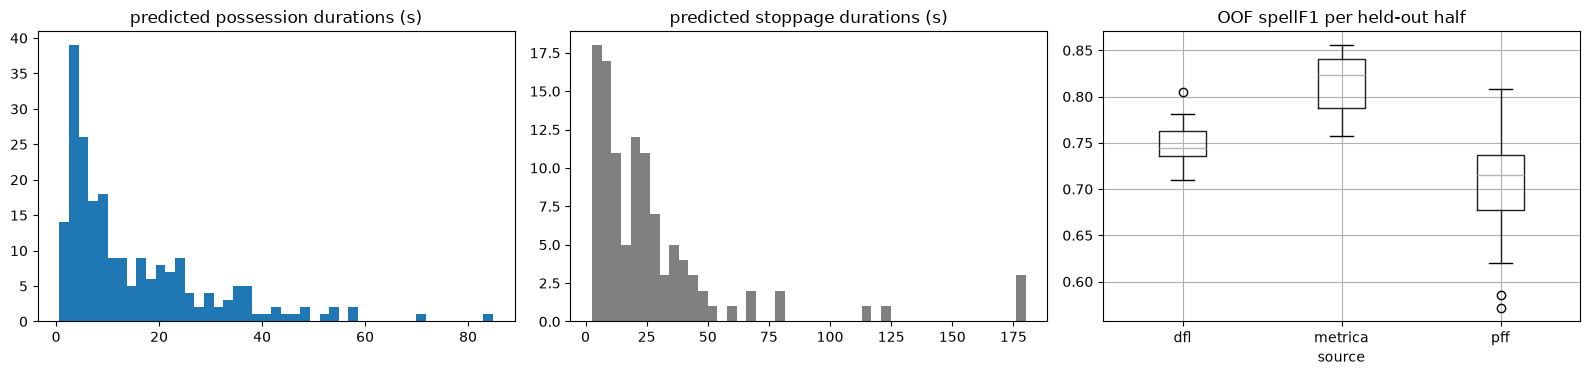

spellF1                                                  macroF1                                                 
          count   mean    std    min    25%    50%    75%    max   count   mean    std    min    25%    50%    75%    max
source                                                                                                                   
dfl        14.0  0.750  0.025  0.710  0.736  0.744  0.763  0.804    14.0  0.921  0.013  0.886  0.919  0.921  0.929  0.938
metrica     6.0  0.814  0.039  0.757  0.788  0.823  0.841  0.856     6.0  0.933  0.012  0.917  0.923  0.935  0.942  0.945
pff        32.0  0.705  0.056  0.571  0.678  0.715  0.737  0.808    32.0  0.904  0.018  0.859  0.894  0.902  0.916  0.931

In [39]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
pl = np.array([(e - s) / 25 for s, e, _ in pm.possession_spells(FINAL, CFG.HALVES)])
ax[0].hist(np.clip(pl, 0, 90), bins=45, color='tab:blue'); ax[0].set_title('predicted possession durations (s)')
dl = np.array([(e - s) / 25 for s, e, k in pm.segments(FINAL, CFG.HALVES) if k == 2])
ax[1].hist(np.clip(dl, 0, 180), bins=45, color='grey'); ax[1].set_title('predicted stoppage durations (s)')
half_df.boxplot(column='spellF1', by='source', ax=ax[2]); ax[2].set_title('OOF spellF1 per held-out half'); plt.suptitle('')
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'full_match_durations.png', dpi=120); plt.show()
half_df.groupby('source')[['spellF1', 'macroF1']].describe().round(3)

#### Insights

> The source-weighted OOF score is the honest estimate of full-match performance: its validation features carry the full-match ball-gap pattern rather than the easy public five minutes, and its three sources cover three leagues and three tracking systems. Compare `report.json` across runs rather than the public score, whose bootstrap interval spans about 0.3.

---

# Conclusion and Limitations <a name="11"></a>

---

## What Worked

- **More labelled matches, from the target's own tracker.** Metrica's three public sample games are tiny but they are the only labelled data in Metrica's format and convention, and they moved the closest proxy for the target by about 0.03 spellF1. PFF's 64 World Cup matches add scale and a possession-sequence label with the target's rhythm.
- **Validating on three sources.** Decisions that look good on one league are checked on two others, and the per-source disagreement (Metrica preferring more possessions) is visible instead of averaged away.
- **Domain realism over model capacity.** Every training half is degraded with this match's own ball gaps, player dropouts and position bias.
- **Decoding for the metric**, with costs chosen on held-out spellF1.
- **Explicit, cross-checked evidence terms.** The replay flag and the missing-ball term are each validated against the other rather than tuned on the public window.
- **Checking the possession rhythm on the target match**. The OOF score cannot see that a model which is well calibrated on external halves merges possessions on BAR-ATH; the possession rate per live minute can, and it needs no labels. It enters selection only as a bounded penalty outside a band set by the external labels.

## Provided Assets Not Used

- **Smart Tagging**: coarse fixed-length windows whose team call agrees with the public ground truth on only about 70% of live frames, so it would add noise exactly where the tracking is uncertain.
- **Video pixels**: the tracking already summarises the video, and the broadcast homography validity flag captures the replay signal cheaply.

## Limitations and Next Steps

- The external labels are derived from events (Metrica, PFF) or from another provider's tracking (DFL); none is Metrica's corrected tracking, which defines the ground truth.
- The rhythm reference is an average over three leagues and labelling conventions. A team with Barcelona's style may genuinely have longer possessions than average, which is why the band is +/-10% and the penalty is small: it corrects large departures, not small ones.
- Ball gaps are simulated independently of the label during training; a label-conditional simulation calibrated on BAR-ATH could let the frame models use gap context directly, but it cannot be validated without labelled Metrica ATD.
- Video ball detection on the tactical frames could recover live-play gaps.

## Reproduction

`python regenerate_submission.py` in the repository root rebuilds `False_Five.csv` byte for byte from `artifacts/` (`final_probabilities.npy`, `decoder_evidence.npy`, `decoder.json`). To retrain everything, point `MTAH_DATA_DIR`, `MTAH_REF_DIR` and `MTAH_REPO_DIR` at local copies (or set the `MTAH_GDRIVE_*` variables) and run all cells of this notebook on a GPU machine.
